# TP1 (suite) — Reconnaissance des émotions faciales avec CK+ : HOG, LBP **et Facial Landmarks (LUVLi / dlib)**

**Module : Reconnaissance de formes** · **Descripteurs : HOG, LBP, landmarks géométriques** · **Classifieurs : SVM, Random Forest, XGBoost**

Ce notebook regroupe **(1)** le TP1 complet (parties 1 à 7 : HOG, LBP, fusion, sélection de caractéristiques, analyse finale) et **(2)** la suite du TP : extraction de **68 landmarks faciaux**, état de l'art, caractéristiques géométriques justifiées, fusion avec HOG/LBP, expériences et mini-rapport.

> **Durée.** Compter environ 30 à 60 min sur Colab (CPU) en mode complet, ~10 à 15 min avec `QUICK = True` (XGBoost sur les grands vecteurs HOG est l'étape la plus lente).
>
> **Mode d'emploi.** Exécuter de haut en bas dans Google Colab (GPU facultatif). Mettre `QUICK = True` dans la cellule de configuration pour un essai rapide (grilles réduites). Aucun chiffre de ce notebook n'est pré-écrit : tous les tableaux, courbes et textes d'analyse chiffrés sont **générés à l'exécution** à partir de vos données.

## Plan
| Partie | Contenu |
|---|---|
| 0 | Installation, configuration, outils communs |
| 1 | Chargement, exploration et contrôle de CK+ |
| 2 | Séparation par sujet, déséquilibre, métriques |
| 3 | HOG |
| 4 | LBP |
| 5 | Fusion HOG–LBP |
| 6 | Sélection de caractéristiques |
| 7 | Comparaison TP1 (HOG / LBP / fusion / sélection) |
| 8 | **Suite : état de l'art, landmarks (LUVLi/dlib), caractéristiques géométriques, fusion, expériences** |
| 9 | Analyse finale, matrices de confusion, exemples, conclusion |
| 10 | Mini-rapport (généré) |

# Partie 0 — Installation, configuration et outils communs

In [1]:
import os, re, sys, time, json, glob, hashlib, warnings, subprocess, importlib, itertools
from pathlib import Path
warnings.filterwarnings("ignore")

def ensure(pip_name, import_name=None):
    """Installe un paquet pip s'il est absent."""
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for pkg, imp in [("kagglehub", None), ("scikit-image", "skimage"), ("opencv-python-headless", "cv2"),
                 ("xgboost", None), ("seaborn", None), ("tabulate", None)]:
    ensure(pkg, imp)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from skimage.feature import hog, local_binary_pattern
from skimage import exposure
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import (StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, cross_val_predict)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report)
from sklearn.utils.class_weight import compute_sample_weight, compute_class_weight
from xgboost import XGBClassifier

# ------------------------------------------------------------- configuration
QUICK = False        # True : essais rapides (grilles et nombre d'itérations réduits)
SEED = 42
TEST_FRACTION = 0.20 # part (approximative) des SUJETS réservée au test
N_FOLDS = 5          # validation croisée groupée (par sujet) sur l'apprentissage
N_ITER = 3 if QUICK else 8      # tirages pour RandomizedSearch (RF / XGBoost)
N_JOBS = -1
LM_TTA = 4 if QUICK else 8       # nb de vues (test-time augmentation) pour l'incertitude des landmarks
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("QUICK =", QUICK, "| SEED =", SEED)

QUICK = False | SEED = 42


In [2]:
# ------------------------------------------------------------- outils de métriques
def metrics_dict(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
    }

class BlockScaler(BaseEstimator, TransformerMixin):
    """Standardise chaque colonne (statistiques d'APPRENTISSAGE uniquement, car placé dans le Pipeline)
    puis pondère chaque bloc de caractéristiques par 1/sqrt(dim_bloc) : chaque famille (HOG, LBP, géométrie...)
    contribue alors avec la même 'énergie' totale, quelle que soit sa dimension."""
    def __init__(self, blocks=None, block_weights=None, equalize=True):
        self.blocks = blocks; self.block_weights = block_weights; self.equalize = equalize
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = X.mean(0); self.std_ = X.std(0) + 1e-8
        w = np.ones(X.shape[1])
        if self.equalize:
            blocks = self.blocks or [(0, X.shape[1])]
            for i, (a, b) in enumerate(blocks):
                bw = 1.0 if self.block_weights is None else self.block_weights[i]
                w[a:b] = bw / np.sqrt(b - a)
        self.w_ = w
        return self
    def transform(self, X):
        return (np.asarray(X, dtype=np.float64) - self.mean_) / self.std_ * self.w_

def timeit(fn, *a, **k):
    t = time.perf_counter(); out = fn(*a, **k); return out, time.perf_counter() - t

# Partie 1 — Chargement et exploration de CK+

Le dataset est téléchargé avec `kagglehub` (code imposé). Les images exploitables sont repérées en parcourant l'archive : l'**émotion** est le nom du dossier parent et l'**identifiant du sujet** est extrait du nom de fichier (format CK+ `S010_004_00000017.png` = sujet `S010`, séquence `004`, image `17`).

In [3]:
import kagglehub
KAGGLE_DATASET = "shawon10/ckplus"
DATA_ROOT = Path(kagglehub.dataset_download(KAGGLE_DATASET))
print("DATA_ROOT =", DATA_ROOT)

DATA_ROOT = /kaggle/input/datasets/shawon10/ckplus


In [4]:
EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
KNOWN_EMOS = {"anger", "contempt", "disgust", "fear", "happy", "sadness", "surprise", "neutral"}

all_files = sorted(p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in EXTS)
print("Fichiers image trouvés :", len(all_files))

def parse_subject(stem):
    m = re.match(r"^(S\d+)", stem, flags=re.I) or re.search(r"(S\d{2,})", stem, flags=re.I)
    return m.group(1).upper() if m else None

rows = []
for p in all_files:
    emo = p.parent.name.lower().strip()
    stem = p.stem
    subj = parse_subject(stem)
    parts = stem.split("_")
    seq = "_".join(parts[:2]) if len(parts) >= 3 else None
    rows.append(dict(path=str(p), emotion=emo, subject=subj, sequence=seq, fname=p.name))
df_all = pd.DataFrame(rows)

# On ne garde que les dossiers qui correspondent à des émotions connues (si possible)
if df_all["emotion"].isin(KNOWN_EMOS).any():
    ignored = df_all[~df_all["emotion"].isin(KNOWN_EMOS)]
    if len(ignored):
        print("Dossiers ignorés (pas des émotions) :", ignored["emotion"].value_counts().to_dict())
    df_all = df_all[df_all["emotion"].isin(KNOWN_EMOS)].reset_index(drop=True)
print(df_all["emotion"].value_counts())

Fichiers image trouvés : 1962
emotion
surprise    498
happy       414
disgust     354
anger       270
sadness     168
fear        150
contempt    108
Name: count, dtype: int64


In [5]:
# Lecture des images + contrôles de qualité
imgs, info = [], []
for i, r in df_all.iterrows():
    try:
        raw = Path(r.path).read_bytes()
        im = Image.open(r.path).convert("L")
        a = np.array(im)
        info.append(dict(ok=True, h=a.shape[0], w=a.shape[1], mean=a.mean(), std=a.std(),
                         md5=hashlib.md5(a.tobytes()).hexdigest()))
        imgs.append(a)
    except Exception as e:
        info.append(dict(ok=False, h=np.nan, w=np.nan, mean=np.nan, std=np.nan, md5=None))
        imgs.append(None)
df_all = pd.concat([df_all, pd.DataFrame(info)], axis=1)

# ----- images / étiquettes problématiques
problems = {}
problems["illisibles"] = df_all[~df_all.ok]
good = df_all[df_all.ok]
major_size = good.groupby(["h", "w"]).size().idxmax()
problems["taille différente de la taille majoritaire %s" % (major_size,)] = good[(good.h != major_size[0]) | (good.w != major_size[1])]
problems["sujet non identifiable (nom de fichier)"] = df_all[df_all.subject.isna()]
problems["image quasi constante (std<2)"] = good[good["std"] < 2]
dup = good[good.duplicated("md5", keep=False)]
problems["doublons exacts (même pixels)"] = dup
conflict = dup.groupby("md5")["emotion"].nunique()
problems["doublons avec ÉTIQUETTES DIFFÉRENTES"] = dup[dup.md5.isin(conflict[conflict > 1].index)]
for k, v in problems.items():
    print(f"{k:60s}: {len(v)}")

illisibles                                                  : 0
taille différente de la taille majoritaire (np.int64(48), np.int64(48)): 0
sujet non identifiable (nom de fichier)                     : 0
image quasi constante (std<2)                               : 0
doublons exacts (même pixels)                               : 1962
doublons avec ÉTIQUETTES DIFFÉRENTES                        : 0


In [6]:
# Construction de la structure finale (images exploitables uniquement), tailles harmonisées
IMG = 48                                  # taille de travail (CK+48 : 48x48)
keep = df_all.ok & df_all.subject.notna() & (df_all["std"] >= 2)
keep &= ~df_all.md5.isin(conflict[conflict > 1].index)       # on écarte les doublons contradictoires
df = df_all[keep].copy().reset_index(drop=False).rename(columns={"index": "orig_idx"})
X_img = np.stack([cv2.resize(imgs[i], (IMG, IMG), interpolation=cv2.INTER_AREA) for i in df.orig_idx]).astype(np.uint8)

le = LabelEncoder().fit(df.emotion)
CLASSES = list(le.classes_)
y = le.transform(df.emotion)
groups = df.subject.values
df["y"] = y
print(f"Images exploitables : {len(df)} | sujets : {df.subject.nunique()} | classes : {len(CLASSES)} -> {CLASSES}")
print("Forme du tenseur images :", X_img.shape, X_img.dtype)

Images exploitables : 1962 | sujets : 118 | classes : 7 -> ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
Forme du tenseur images : (1962, 48, 48) uint8


,images,sujets,images/sujet,part (%)
emotion,,,,
anger,270,45,6.0,13.8
contempt,108,18,6.0,5.5
disgust,354,59,6.0,18.0
fear,150,25,6.0,7.6
happy,414,69,6.0,21.1
sadness,168,28,6.0,8.6
surprise,498,83,6.0,25.4


Ratio d'imbalance (classe max / classe min) = 4.6


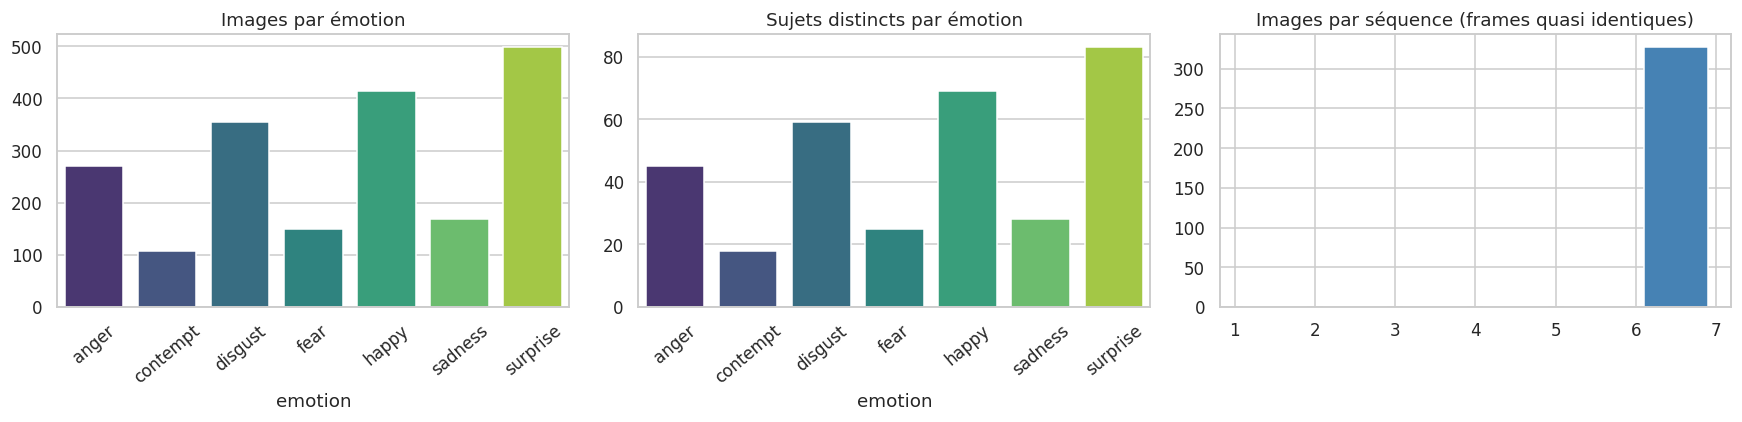

Images par sujet : min/médiane/max = [6.0, 18.0, 36.0]


In [7]:
# ----- distributions
cnt = df.emotion.value_counts().reindex(CLASSES)
subj_per_emo = df.groupby("emotion").subject.nunique().reindex(CLASSES)
summary = pd.DataFrame({"images": cnt, "sujets": subj_per_emo,
                        "images/sujet": (cnt / subj_per_emo).round(2),
                        "part (%)": (100 * cnt / cnt.sum()).round(1)})
display(summary)
imb_ratio = cnt.max() / cnt.min()
print(f"Ratio d'imbalance (classe max / classe min) = {imb_ratio:.1f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(x=cnt.index, y=cnt.values, ax=ax[0], palette="viridis"); ax[0].set_title("Images par émotion")
sns.barplot(x=subj_per_emo.index, y=subj_per_emo.values, ax=ax[1], palette="viridis"); ax[1].set_title("Sujets distincts par émotion")
for a in ax[:2]: a.tick_params(axis="x", rotation=40)
seq_counts = df.groupby("sequence").size() if df.sequence.notna().any() else pd.Series(dtype=int)
if len(seq_counts):
    ax[2].hist(seq_counts.values, bins=range(1, int(seq_counts.max()) + 2), color="steelblue", rwidth=.8)
    ax[2].set_title("Images par séquence (frames quasi identiques)")
plt.tight_layout(); plt.show()
print("Images par sujet : min/médiane/max =", df.groupby("subject").size().agg(["min", "median", "max"]).tolist())

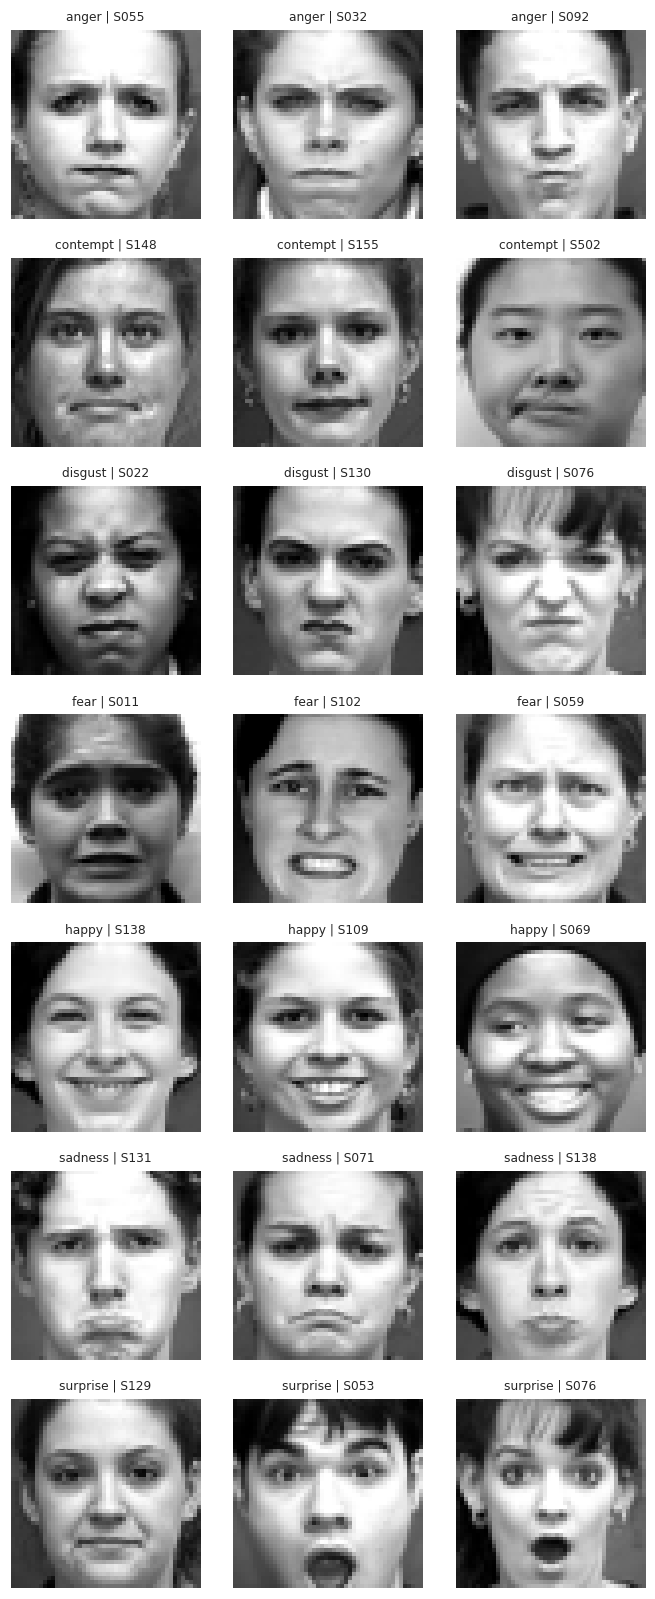

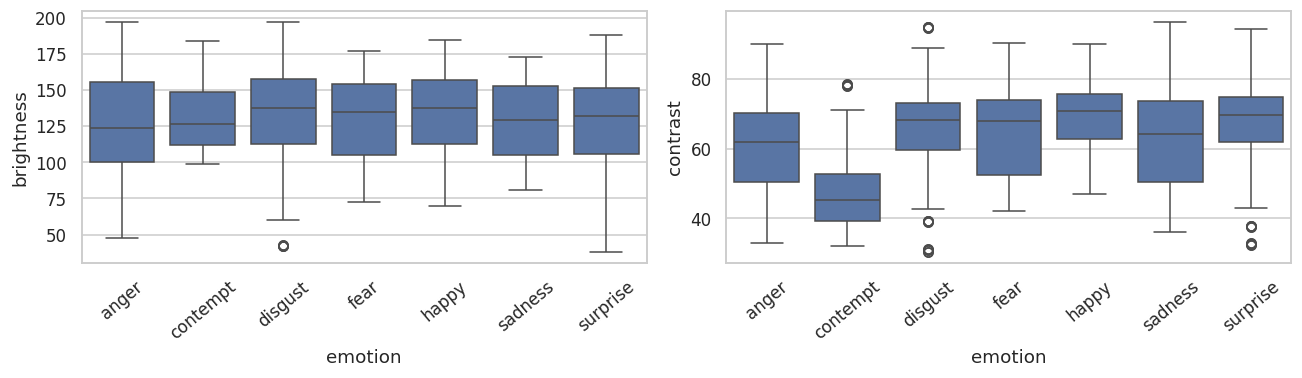

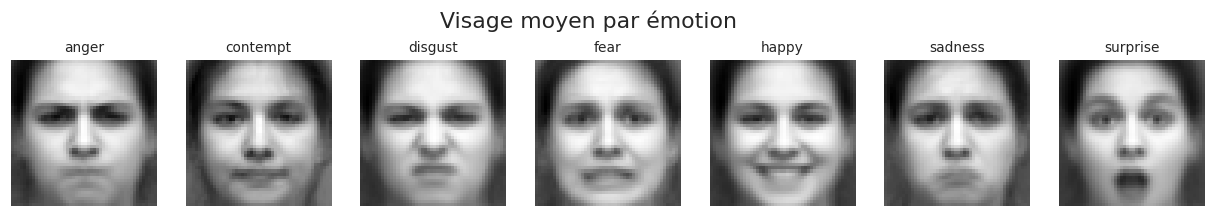

In [8]:
# ----- grille d'exemples annotés (3 par classe)
n_ex = 3
fig, axes = plt.subplots(len(CLASSES), n_ex, figsize=(2.1 * n_ex, 2.1 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    idx = df.index[df.emotion == c].to_numpy()
    pick = rng.choice(idx, size=min(n_ex, len(idx)), replace=False)
    for k in range(n_ex):
        ax = axes[r, k]; ax.axis("off")
        if k < len(pick):
            ax.imshow(X_img[pick[k]], cmap="gray"); ax.set_title(f"{c} | {df.subject[pick[k]]}", fontsize=8)
plt.tight_layout(); plt.show()

# ----- variations d'intensité / cadrage
df["brightness"] = X_img.reshape(len(X_img), -1).mean(1)
df["contrast"] = X_img.reshape(len(X_img), -1).std(1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.boxplot(data=df, x="emotion", y="brightness", order=CLASSES, ax=ax[0]); ax[0].tick_params(axis="x", rotation=40)
sns.boxplot(data=df, x="emotion", y="contrast", order=CLASSES, ax=ax[1]); ax[1].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()
mean_faces = np.stack([X_img[df.emotion == c].mean(0) for c in CLASSES])
fig, axes = plt.subplots(1, len(CLASSES), figsize=(2 * len(CLASSES), 2.3))
for a, f, c in zip(axes, mean_faces, CLASSES):
    a.imshow(f, cmap="gray"); a.set_title(c, fontsize=9); a.axis("off")
plt.suptitle("Visage moyen par émotion"); plt.show()

In [9]:
# ----- texte d'analyse généré à partir des valeurs réelles
lines = []
lines.append(f"1) Équilibre : classe max = {cnt.idxmax()} ({cnt.max()} images), classe min = {cnt.idxmin()} ({cnt.min()}), ratio = {imb_ratio:.1f}. "
             + ("Le dataset est DÉSÉQUILIBRÉ." if imb_ratio > 1.5 else "Le dataset est à peu près équilibré."))
ips = summary["images/sujet"]
lines.append(f"2) Images vs sujets : images/sujet varie de {ips.min()} ({ips.idxmin()}) à {ips.max()} ({ips.idxmax()}). "
             "Le nombre d'images d'une classe n'est donc PAS le nombre de sujets : plusieurs frames d'une même séquence sont quasi identiques.")
lines.append(f"   Classes les moins représentées en SUJETS : {subj_per_emo.sort_values().head(3).to_dict()}.")
print("\n".join(lines))

1) Équilibre : classe max = surprise (498 images), classe min = contempt (108), ratio = 4.6. Le dataset est DÉSÉQUILIBRÉ.
2) Images vs sujets : images/sujet varie de 6.0 (anger) à 6.0 (anger). Le nombre d'images d'une classe n'est donc PAS le nombre de sujets : plusieurs frames d'une même séquence sont quasi identiques.
   Classes les moins représentées en SUJETS : {'contempt': 18, 'fear': 25, 'sadness': 28}.


### Réponses — Partie 1 (à lire avec les sorties ci-dessus)

1. **Équilibre.** La cellule précédente affiche les effectifs, les parts et le ratio max/min : un ratio nettement supérieur à ~1,5 indique un déséquilibre. CK+ est construit à partir de séquences dont seules certaines portent une étiquette d'émotion validée, d'où des classes très inégales (*contempt*, *fear*, *sadness* sont généralement petites).
2. **Images ≠ sujets.** Non : CK+ fournit plusieurs frames par séquence (les dernières images, proches du pic d'expression) ; une classe « riche en images » peut ne contenir que quelques sujets. Le tableau « images/sujet » le quantifie. Le nombre de **sujets** par classe, et non d'images, détermine la vraie diversité.
3. **Émotions proches.** Visuellement, *anger / disgust / sadness / contempt* partagent des mouvements faibles (sourcils, commissures) et sont les plus confondues dans la littérature ; *happy* et *surprise* ont des signatures fortes (bouche étirée / bouche ouverte, sourcils levés). Les visages moyens ci-dessus aident à le voir.
4. **Variations.** Les boîtes à moustaches montrent les variations de luminosité/contraste ; CK+ est enregistré en laboratoire (éclairage frontal, pose quasi frontale) donc ces variations sont **faibles** par rapport à des images « in the wild », mais elles existent entre sujets (peau, éclairage, cadrage du recadrage automatique) et entre intensités d'expression.
5. **Limite des expressions posées.** Les expressions sont jouées sur consigne, exagérées et au pic d'intensité ; elles diffèrent des expressions spontanées (plus subtiles, asymétriques, courtes). Un score élevé sur CK+ surestime donc la performance réelle (voir Partie 9).

# Partie 2 — Protocole expérimental et déséquilibre

**Principe.** Découpage **par sujet** (`StratifiedGroupKFold` : groupes = sujets, stratification par émotion). Un sous-ensemble de sujets est réservé au test et n'est plus touché avant l'évaluation finale. Toute la sélection de modèle (grilles d'hyperparamètres, choix du descripteur, nombre de caractéristiques) utilise une **validation croisée groupée sur l'apprentissage seul**.

In [10]:
def make_group_split(y, groups, test_fraction=TEST_FRACTION, seed=SEED, max_try=200):
    """Découpage par sujet ; on cherche une graine pour laquelle toutes les classes sont présentes
    (>=2 images) dans le test ET l'apprentissage — la graine est choisie SANS regarder aucun score."""
    n_splits = int(round(1 / test_fraction))
    for k in range(max_try):
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed + k)
        tr, te = next(sgkf.split(np.zeros(len(y)), y, groups))
        if (np.bincount(y[te], minlength=y.max() + 1) >= 2).all() and (np.bincount(y[tr], minlength=y.max() + 1) >= 2).all():
            return tr, te, seed + k
    raise RuntimeError("Aucun découpage valide trouvé")

tr_idx, te_idx, split_seed = make_group_split(y, groups)
X_tr_img, X_te_img = X_img[tr_idx], X_img[te_idx]
y_tr, y_te = y[tr_idx], y[te_idx]
g_tr, g_te = groups[tr_idx], groups[te_idx]

# ----- PREUVE d'absence de fuite
common = set(g_tr) & set(g_te)
assert len(common) == 0, f"FUITE : sujets communs {common}"
assert set(tr_idx).isdisjoint(te_idx)
print(f"graine de découpage = {split_seed}")
print(f"Apprentissage : {len(tr_idx)} images, {len(set(g_tr))} sujets | Test : {len(te_idx)} images, {len(set(g_te))} sujets")
print("Sujets communs apprentissage/test :", len(common), "-> OK, aucune fuite")

dist = pd.DataFrame({"train": np.bincount(y_tr, minlength=len(CLASSES)), "test": np.bincount(y_te, minlength=len(CLASSES))}, index=CLASSES)
dist["train_sujets"] = [len(set(g_tr[y_tr == k])) for k in range(len(CLASSES))]
dist["test_sujets"] = [len(set(g_te[y_te == k])) for k in range(len(CLASSES))]
display(dist)

# ----- plis de validation croisée GROUPÉS (identiques pour toutes les expériences)
cv_splits = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y_tr)), y_tr, g_tr))
for i, (a, b) in enumerate(cv_splits):
    assert set(g_tr[a]).isdisjoint(g_tr[b])
print("Plis CV :", [len(b) for a, b in cv_splits], "- aucun sujet partagé entre plis d'apprentissage/validation : OK")

# ----- déséquilibre : pondération des classes calculée sur l'apprentissage uniquement
cw = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_tr)
print("Poids de classe (train) :", {c: round(float(w), 2) for c, w in zip(CLASSES, cw)})
sw_tr = compute_sample_weight("balanced", y_tr)

graine de découpage = 42
Apprentissage : 1590 images, 95 sujets | Test : 372 images, 23 sujets
Sujets communs apprentissage/test : 0 -> OK, aucune fuite


,train,test,train_sujets,test_sujets
anger,210,60,35,10
contempt,84,24,14,4
disgust,294,60,49,10
fear,120,30,20,5
happy,348,66,58,11
sadness,120,48,20,8
surprise,414,84,69,14


Plis CV : [324, 360, 252, 360, 294] - aucun sujet partagé entre plis d'apprentissage/validation : OK
Poids de classe (train) : {'anger': 1.08, 'contempt': 2.7, 'disgust': 0.77, 'fear': 1.89, 'happy': 0.65, 'sadness': 1.89, 'surprise': 0.55}


### Réponses — Partie 2

1. **Pourquoi pas un découpage aléatoire par image ?** Dans CK+, un même sujet produit plusieurs images quasi identiques (frames consécutives d'une séquence, même visage, même éclairage). Un tirage aléatoire place des frames d'un même sujet dans l'apprentissage **et** le test : le modèle peut reconnaître *la personne* ou *la séquence* au lieu de l'émotion → fuite de données et scores gonflés.
2. **Vérification.** `assert` explicites : intersection des sujets apprentissage/test vide, indices disjoints, et plis de CV disjoints en sujets (cellule ci-dessus).
3. **Déséquilibre.** Stratégie : **pondération des classes** (`class_weight='balanced'` pour SVM et RF, `sample_weight` équilibré pour XGBoost), calculée uniquement sur l'apprentissage. Raison : aucun échantillon synthétique (SMOTE) n'est généré, donc pas de risque de créer des « faux sujets » ni de contaminer les plis ; coût nul ; compatible avec les trois classifieurs. Un ablation (avec / sans poids) est faite en Partie 9.
4. **Métriques.** **Macro-F1** (critère principal de sélection), exactitude équilibrée (*balanced accuracy* = rappel moyen), accuracy (indicative), F1 pondéré, précision/rappel macro, matrices de confusion normalisées et F1 par classe.
5. **Pourquoi macro-F1 ?** Elle moyenne le F1 de chaque classe avec le même poids : une classe rare mal reconnue fait baisser le score, alors que l'accuracy est dominée par les classes majoritaires.

## Infrastructure commune d'optimisation (utilisée par toutes les parties)

Tous les modèles passent par un `Pipeline` : `BlockScaler` (SVM) → `SelectKBest` (optionnel, appris **dans chaque pli**) → classifieur.
La recherche d'hyperparamètres utilise **exactement les mêmes plis groupés par sujet** (`cv_splits`) et le même critère (**macro-F1**). Le jeu de test n'est utilisé qu'une fois, après refit sur tout l'apprentissage.

In [11]:
from sklearn.base import ClassifierMixin

class SafeXGB(BaseEstimator, ClassifierMixin):
    """XGBoost tolérant : gère un pli d'apprentissage où une classe est absente (remappage des étiquettes)."""
    def __init__(self, n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5):
        self.n_estimators = n_estimators; self.max_depth = max_depth; self.learning_rate = learning_rate
        self.subsample = subsample; self.colsample_bytree = colsample_bytree
    def fit(self, X, y, sample_weight=None):
        self.classes_ = np.unique(y)
        mp = {c: i for i, c in enumerate(self.classes_)}
        yy = np.array([mp[c] for c in y])
        self.m_ = XGBClassifier(n_estimators=self.n_estimators, max_depth=self.max_depth, learning_rate=self.learning_rate,
                                subsample=self.subsample, colsample_bytree=self.colsample_bytree, objective="multi:softprob",
                                tree_method="hist", max_bin=64, n_jobs=1, random_state=SEED, eval_metric="mlogloss", verbosity=0)
        self.m_.fit(X, yy, sample_weight=sample_weight)
        return self
    def predict_proba(self, X):
        return self.m_.predict_proba(X)
    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

def build_pipe(name, blocks=None, sel_k=None):
    steps = []
    if name == "SVM":
        steps.append(("prep", BlockScaler(blocks=blocks)))
    if sel_k is not None:
        steps.append(("sel", SelectKBest(f_classif, k=sel_k)))
    if name == "SVM":
        clf = SVC(class_weight="balanced", random_state=SEED)
    elif name == "RF":
        clf = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=1, random_state=SEED)
    elif name == "XGB":
        clf = SafeXGB()
    steps.append(("clf", clf))
    return Pipeline(steps)

GRIDS = {
    "SVM": [{"clf__kernel": ["linear"], "clf__C": [1, 10, 100, 1000]},
            {"clf__kernel": ["rbf"], "clf__C": [1, 10, 100, 1000], "clf__gamma": ["scale", "auto"]}],
    "RF":  {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 15, 30],
            "clf__max_features": ["sqrt", "log2", 0.1], "clf__min_samples_leaf": [1, 2]},
    "XGB": {"clf__n_estimators": [100, 200], "clf__max_depth": [3, 5], "clf__learning_rate": [0.1, 0.2],
            "clf__subsample": [0.7, 1.0], "clf__colsample_bytree": [0.1, 0.3]},
}

RESULTS, MODELS = [], {}

def run_experiment(rep, Xall, blocks=None, sel_k=None, clfs=("SVM", "RF", "XGB"), extract_time=np.nan, verbose=True):
    """Optimise (CV groupée sur l'apprentissage) puis évalue UNE fois sur le test."""
    Xtr, Xte = Xall[tr_idx], Xall[te_idx]
    out = []
    for name in clfs:
        pipe = build_pipe(name, blocks, sel_k)
        if name == "SVM":
            search = GridSearchCV(pipe, GRIDS["SVM"], scoring="f1_macro", cv=cv_splits, n_jobs=N_JOBS, refit=True)
        else:
            search = RandomizedSearchCV(pipe, GRIDS[name], n_iter=N_ITER, scoring="f1_macro", cv=cv_splits,
                                        n_jobs=N_JOBS, refit=True, random_state=SEED)
        fit_params = {"clf__sample_weight": sw_tr} if name == "XGB" else {}
        t0 = time.perf_counter(); search.fit(Xtr, y_tr, **fit_params); t_search = time.perf_counter() - t0
        r = search.cv_results_; i = search.best_index_
        folds = [r[f"split{k}_test_score"][i] for k in range(N_FOLDS)]
        best = search.best_estimator_
        t0 = time.perf_counter(); pred = best.predict(Xte); t_pred = (time.perf_counter() - t0) / len(Xte) * 1000
        row = dict(representation=rep, classifier=name,
                   n_features=Xall.shape[1], n_used=(min(sel_k, Xall.shape[1]) if sel_k else Xall.shape[1]),
                   best_params={k.replace("clf__", ""): v for k, v in search.best_params_.items()},
                   cv_f1_mean=float(np.mean(folds)), cv_f1_std=float(np.std(folds)), cv_folds=folds,
                   extract_s=extract_time, search_s=t_search, refit_s=float(search.refit_time_), pred_ms_img=t_pred,
                   **{f"test_{k}": v for k, v in metrics_dict(y_te, pred).items()})
        RESULTS.append(row); out.append(row); REP_X[rep] = Xall
        MODELS[(rep, name)] = dict(est=best, pred=pred, sel_k=sel_k, blocks=blocks)
        if verbose:
            print(f"[{rep:38s} | {name:3s}] CV macro-F1 = {row['cv_f1_mean']:.3f} ± {row['cv_f1_std']:.3f} | "
                  f"test macro-F1 = {row['test_macro_f1']:.3f} | acc = {row['test_accuracy']:.3f} | {t_search:.0f}s")
    return pd.DataFrame(out)

def results_df():
    d = pd.DataFrame(RESULTS)
    return d

def best_row(prefix, exact=False):
    d = results_df(); d = d[(d.representation == prefix) if exact else d.representation.str.startswith(prefix)]
    return d.sort_values("cv_f1_mean", ascending=False).iloc[0]      # sélection sur la VALIDATION, jamais sur le test

REP_X = {}   # représentation -> matrice de caractéristiques complète (toutes les images)

def quick_cv(Xall, blocks=None):
    """Évaluation rapide d'une représentation : SVM linéaire pondéré, macro-F1 en CV groupée (apprentissage seul)."""
    pipe = Pipeline([("prep", BlockScaler(blocks=blocks)), ("clf", SVC(kernel="linear", C=10, class_weight="balanced"))])
    s = cross_val_score(pipe, Xall[tr_idx], y_tr, cv=cv_splits, scoring="f1_macro", n_jobs=N_JOBS)
    return s.mean(), s.std()

def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES, annot_kws={"size": 7})
    ax.set_title(title, fontsize=9); ax.set_xlabel("prédit"); ax.set_ylabel("vrai")
    ax.tick_params(axis="x", rotation=45)

def top_confusions(y_true, y_pred, k=4):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)), normalize="true")
    pairs = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j]
    return sorted(pairs, key=lambda t: -t[2])[:k]

# Partie 3 — Étude du descripteur HOG

**Principe.** HOG découpe l'image en *cellules*, y calcule un histogramme de **directions de gradient** pondéré par la norme du gradient, puis normalise par *blocs* de cellules voisines (robustesse à l'éclairage local). Il encode donc la **forme locale** (contours des yeux, sourcils, bouche, plis nasogéniens) sans se préoccuper de l'intensité absolue.

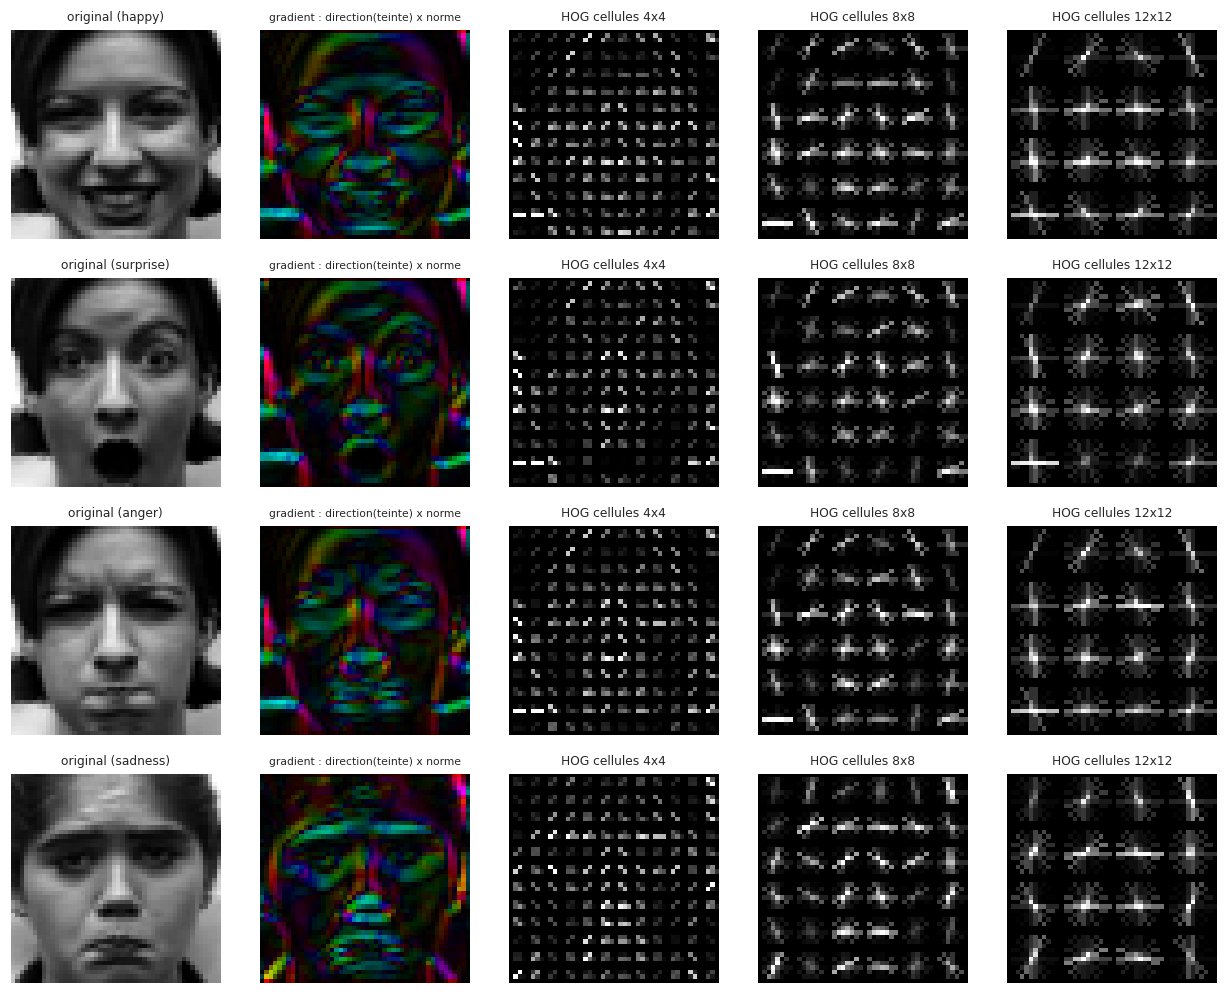

In [12]:
def grad_maps(img):
    f = img.astype(np.float32)
    gx = cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3); gy = cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=3)
    return np.hypot(gx, gy), (np.arctan2(gy, gx) * 180 / np.pi) % 180

from matplotlib.colors import hsv_to_rgb
vis_cfgs = {"cellules 4x4": dict(orientations=9, pixels_per_cell=(4, 4), cells_per_block=(2, 2)),
            "cellules 8x8": dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)),
            "cellules 12x12": dict(orientations=9, pixels_per_cell=(12, 12), cells_per_block=(2, 2))}
show_classes = [c for c in ["happy", "surprise", "anger", "sadness"] if c in CLASSES][:4]
fig, axes = plt.subplots(len(show_classes), 2 + len(vis_cfgs), figsize=(2.3 * (2 + len(vis_cfgs)), 2.3 * len(show_classes)))
for r, c in enumerate(show_classes):
    im = X_img[np.where(df.emotion.values == c)[0][0]]
    mag, ang = grad_maps(im)
    hsv = np.dstack([ang / 180, np.ones_like(mag), mag / (mag.max() + 1e-8)])
    axes[r, 0].imshow(im, cmap="gray"); axes[r, 0].set_title(f"original ({c})", fontsize=8)
    axes[r, 1].imshow(hsv_to_rgb(hsv)); axes[r, 1].set_title("gradient : direction(teinte) x norme", fontsize=7)
    for k, (nm, kw) in enumerate(vis_cfgs.items()):
        _, himg = hog(im, visualize=True, block_norm="L2-Hys", **kw)
        axes[r, 2 + k].imshow(exposure.rescale_intensity(himg, in_range=(0, np.percentile(himg, 99.5) + 1e-8)), cmap="gray")
        axes[r, 2 + k].set_title(f"HOG {nm}", fontsize=8)
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.show()

,config,orientations,cell,bloc,dim,temps_s_pour_toutes_les_images,cv_macroF1,cv_std
6,ppc6_o9_b3,9,6,3,2916,2.00,0.8085,0.0227
1,ppc6_o9,9,6,2,1764,2.54,0.7821,0.0161
0,ppc4_o9,9,4,2,4356,5.45,0.7721,0.0646
5,ppc8_o12,12,8,2,1200,1.64,0.7705,0.0579
2,ppc8_o9,9,8,2,900,1.55,0.7645,0.0698
4,ppc8_o6,6,8,2,600,1.44,0.7511,0.0410
3,ppc12_o9,9,12,2,324,0.94,0.6180,0.0666


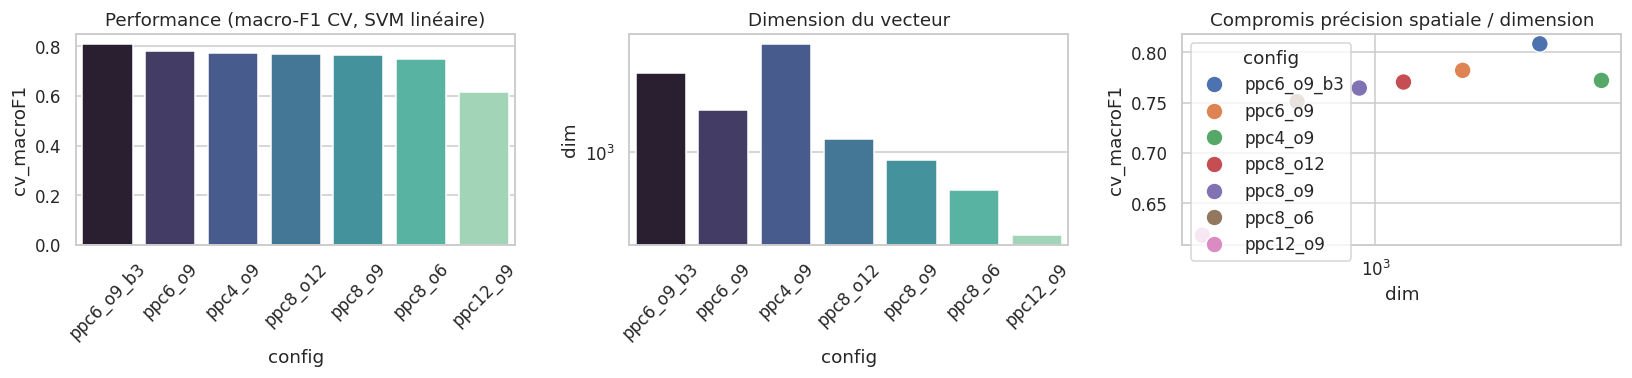

In [13]:
# ----- Étude des hyperparamètres HOG : dimension, temps, performance (CV groupée, apprentissage seul)
HOG_CONFIGS = {
    "ppc4_o9":  dict(orientations=9,  pixels_per_cell=(4, 4),   cells_per_block=(2, 2)),
    "ppc6_o9":  dict(orientations=9,  pixels_per_cell=(6, 6),   cells_per_block=(2, 2)),
    "ppc8_o9":  dict(orientations=9,  pixels_per_cell=(8, 8),   cells_per_block=(2, 2)),
    "ppc12_o9": dict(orientations=9,  pixels_per_cell=(12, 12), cells_per_block=(2, 2)),
    "ppc8_o6":  dict(orientations=6,  pixels_per_cell=(8, 8),   cells_per_block=(2, 2)),
    "ppc8_o12": dict(orientations=12, pixels_per_cell=(8, 8),   cells_per_block=(2, 2)),
    "ppc6_o9_b3": dict(orientations=9, pixels_per_cell=(6, 6),  cells_per_block=(3, 3)),
}
if QUICK:
    HOG_CONFIGS = {k: v for k, v in HOG_CONFIGS.items() if k in ("ppc4_o9", "ppc8_o9", "ppc12_o9", "ppc8_o12")}

def extract_hog(X, **kw):
    return np.stack([hog(im, feature_vector=True, block_norm="L2-Hys", **kw) for im in X]).astype(np.float32)

HOG_X, HOG_TIME, rows = {}, {}, []
for nm, kw in HOG_CONFIGS.items():
    f, t = timeit(extract_hog, X_img, **kw)
    HOG_X[nm], HOG_TIME[nm] = f, t
    m, s = quick_cv(f)
    rows.append(dict(config=nm, orientations=kw["orientations"], cell=kw["pixels_per_cell"][0], bloc=kw["cells_per_block"][0],
                     dim=f.shape[1], temps_s_pour_toutes_les_images=round(t, 2), cv_macroF1=round(m, 4), cv_std=round(s, 4)))
hog_study = pd.DataFrame(rows).sort_values("cv_macroF1", ascending=False)
display(hog_study)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.barplot(data=hog_study, x="config", y="cv_macroF1", ax=ax[0], palette="mako"); ax[0].set_title("Performance (macro-F1 CV, SVM linéaire)")
sns.barplot(data=hog_study, x="config", y="dim", ax=ax[1], palette="mako"); ax[1].set_title("Dimension du vecteur"); ax[1].set_yscale("log")
sns.scatterplot(data=hog_study, x="dim", y="cv_macroF1", hue="config", s=120, ax=ax[2]); ax[2].set_xscale("log"); ax[2].set_title("Compromis précision spatiale / dimension")
for a in ax[:2]: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [14]:
# ----- Optimisation de SVM / RF / XGBoost pour les 2 meilleures configurations HOG (choisies sur la VALIDATION)
top_hog = hog_study.config.head(2).tolist()
print("Configurations HOG retenues :", top_hog)
for nm in top_hog:
    run_experiment(f"HOG|{nm}", HOG_X[nm], extract_time=HOG_TIME[nm])

hog_res = results_df().query("representation.str.startswith('HOG')", engine="python")
display(hog_res[["representation", "classifier", "n_features", "best_params", "cv_f1_mean", "cv_f1_std",
                 "test_macro_f1", "test_accuracy", "refit_s", "pred_ms_img"]].round(4))
b = best_row("HOG"); HOG_BEST_CFG = b.representation.split("|")[1]; HOG_BEST_CLF = b.classifier
print(f"\n=> Meilleure combinaison HOG (validation) : {HOG_BEST_CFG} + {HOG_BEST_CLF} (CV macro-F1 = {b.cv_f1_mean:.3f})")

Configurations HOG retenues : ['ppc6_o9_b3', 'ppc6_o9']
[HOG|ppc6_o9_b3                         | SVM] CV macro-F1 = 0.832 ± 0.035 | test macro-F1 = 0.846 | acc = 0.882 | 67s
[HOG|ppc6_o9_b3                         | RF ] CV macro-F1 = 0.600 ± 0.051 | test macro-F1 = 0.668 | acc = 0.742 | 433s
[HOG|ppc6_o9_b3                         | XGB] CV macro-F1 = 0.693 ± 0.021 | test macro-F1 = 0.666 | acc = 0.763 | 312s
[HOG|ppc6_o9                            | SVM] CV macro-F1 = 0.817 ± 0.042 | test macro-F1 = 0.816 | acc = 0.871 | 40s
[HOG|ppc6_o9                            | RF ] CV macro-F1 = 0.628 ± 0.057 | test macro-F1 = 0.675 | acc = 0.763 | 281s
[HOG|ppc6_o9                            | XGB] CV macro-F1 = 0.701 ± 0.013 | test macro-F1 = 0.693 | acc = 0.780 | 167s


,representation,classifier,n_features,best_params,cv_f1_mean,cv_f1_std,test_macro_f1,test_accuracy,refit_s,pred_ms_img
0,HOG|ppc6_o9_b3,SVM,2916,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.8317,0.0352,0.8457,0.8817,3.7062,3.6639
1,HOG|ppc6_o9_b3,RF,2916,"{'n_estimators': 400, 'min_samples_leaf': 2, '...",0.5996,0.0512,0.6676,0.7419,89.8104,0.1034
2,HOG|ppc6_o9_b3,XGB,2916,"{'subsample': 1.0, 'n_estimators': 100, 'max_d...",0.6932,0.0210,0.6655,0.7634,13.5298,0.0216
3,HOG|ppc6_o9,SVM,1764,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.8175,0.0416,0.8165,0.8710,1.7716,1.7934
4,HOG|ppc6_o9,RF,1764,"{'n_estimators': 400, 'min_samples_leaf': 2, '...",0.6280,0.0566,0.6745,0.7634,54.6590,0.1281
5,HOG|ppc6_o9,XGB,1764,"{'subsample': 1.0, 'n_estimators': 100, 'max_d...",0.7013,0.0128,0.6929,0.7796,7.1019,0.0167



=> Meilleure combinaison HOG (validation) : ppc6_o9_b3 + SVM (CV macro-F1 = 0.832)


Corrélation CV macro-F1 vs test macro-F1 (modèles HOG) : 0.93


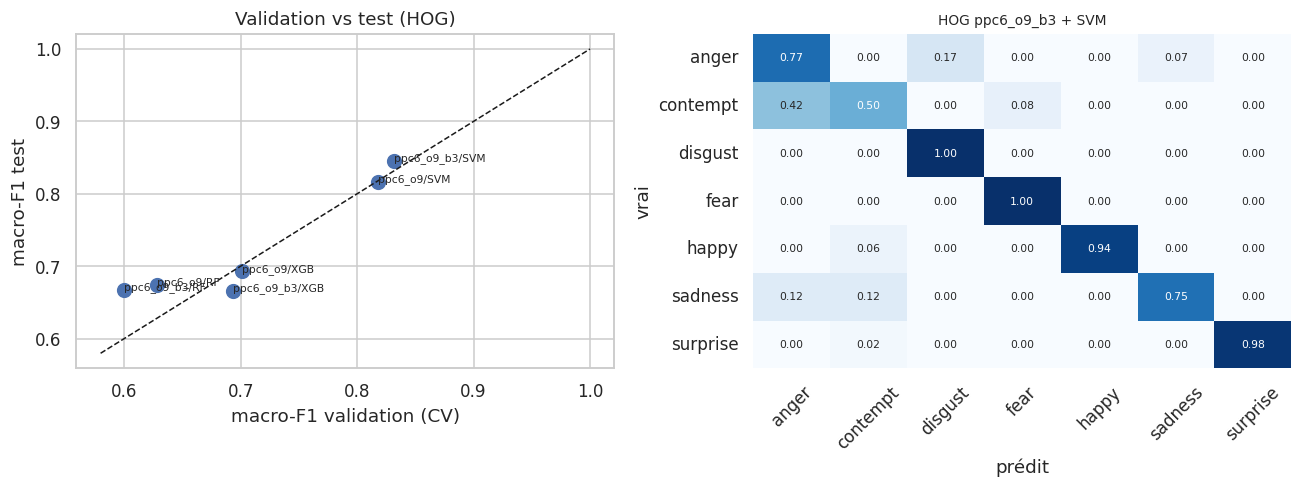

Confusions HOG les plus fréquentes : [('contempt', 'anger', np.float64(0.42)), ('anger', 'disgust', np.float64(0.17)), ('sadness', 'anger', np.float64(0.12)), ('sadness', 'contempt', np.float64(0.12))]
              precision    recall  f1-score   support

       anger       0.74      0.77      0.75        60
    contempt       0.50      0.50      0.50        24
     disgust       0.86      1.00      0.92        60
        fear       0.94      1.00      0.97        30
       happy       1.00      0.94      0.97        66
     sadness       0.90      0.75      0.82        48
    surprise       1.00      0.98      0.99        84

    accuracy                           0.88       372
   macro avg       0.85      0.85      0.85       372
weighted avg       0.89      0.88      0.88       372



In [15]:
# ----- cohérence validation / test + confusions du meilleur modèle HOG
d = hog_res
print("Corrélation CV macro-F1 vs test macro-F1 (modèles HOG) : %.2f" % np.corrcoef(d.cv_f1_mean, d.test_macro_f1)[0, 1] if len(d) > 2 else "")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(d.cv_f1_mean, d.test_macro_f1, s=80)
for _, r in d.iterrows(): ax[0].annotate(f"{r.representation.split('|')[1]}/{r.classifier}", (r.cv_f1_mean, r.test_macro_f1), fontsize=7)
lo = min(d.cv_f1_mean.min(), d.test_macro_f1.min()) - .02; ax[0].plot([lo, 1], [lo, 1], "k--", lw=1)
ax[0].set_xlabel("macro-F1 validation (CV)"); ax[0].set_ylabel("macro-F1 test"); ax[0].set_title("Validation vs test (HOG)")
mb = MODELS[(f"HOG|{HOG_BEST_CFG}", HOG_BEST_CLF)]
plot_cm(ax[1], y_te, mb["pred"], f"HOG {HOG_BEST_CFG} + {HOG_BEST_CLF}")
plt.tight_layout(); plt.show()
print("Confusions HOG les plus fréquentes :", [(a, b_, round(v, 2)) for a, b_, v in top_confusions(y_te, mb["pred"])])
print(classification_report(y_te, mb["pred"], target_names=CLASSES, zero_division=0))

### Réponses — Partie 3 (à lire avec les tableaux et courbes ci-dessus)

1. **Informations mises en évidence.** Les contours à fort gradient : bord des sourcils, paupières, plis du front et nasogéniens, contour des lèvres et ouverture de la bouche. La carte « direction × norme » montre que l'essentiel de l'énergie se concentre sur ces zones expressives, pas sur les joues ni le front lisse.
2. **Taille des cellules.** Petites cellules (4×4) → représentation spatialement fine, sensible à de petits déplacements/bruit ; grandes cellules (12×12) → histogrammes plus robustes mais plus « flous » (perte de localisation des détails comme les rides). Les images HOG des trois tailles ci-dessus l'illustrent.
3. **Compromis précision spatiale / dimension.** La dimension varie comme `(n_cellules − bloc + 1)² × bloc² × orientations` : diviser la cellule par 2 multiplie la dimension environ par 4 (tableau + graphique de dispersion). Plus de dimension = plus de détail mais plus de risque de sur-apprentissage avec peu de sujets et un coût de calcul croissant.
4. **Paramètres les plus influents.** Lire le tableau `hog_study` : comparer les lignes qui ne diffèrent que par la taille de cellule, puis par le nombre d'orientations ou la taille de bloc. La cellule affecte à la fois la dimension et la performance ; les orientations ont en général un effet plus faible.
5. **Meilleur classifieur avec HOG.** Voir le tableau des résultats (critère : CV macro-F1). Pour des descripteurs de grande dimension avec peu d'échantillons, un SVM bien régularisé est typiquement favorisé ; RF/XGBoost travaillent par seuils sur des caractéristiques individuelles très redondantes.
6. **Cohérence validation / test.** Le nuage de points valide/test et la corrélation affichés quantifient la cohérence ; un écart systématique s'explique par la petite taille du test (peu de sujets par classe) et par la sélection optimiste sur la validation.
7. **Émotions difficiles.** Voir `top_confusions` et le rapport de classification : ce sont typiquement les expressions subtiles et voisines (*anger / sadness / contempt / disgust*).

# Partie 4 — Étude du descripteur LBP

**Principe.** Pour chaque pixel, LBP compare l'intensité à celle de `P` voisins sur un cercle de rayon `R` et forme un code binaire (motif de micro-texture : bord, coin, point, zone plate). Les motifs *uniformes* (≤ 2 transitions 0↔1) regroupent la majorité des motifs utiles et réduisent la dimension à `P+2` bins. L'image est ensuite résumée par des **histogrammes par cellules** (grille), concaténés ; une transformation racine (Hellinger) rend les histogrammes plus adaptés aux noyaux euclidiens.

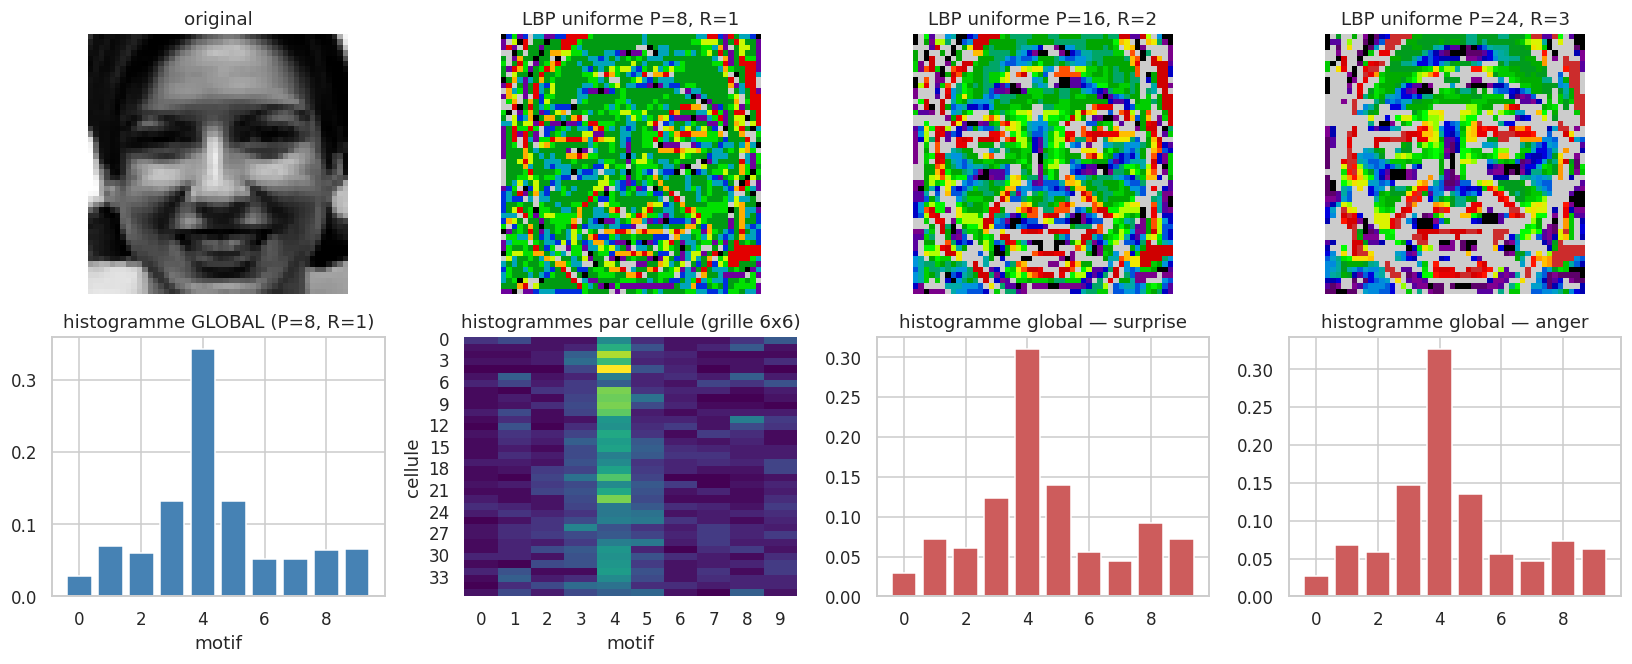

In [16]:
def lbp_code(img, P, R, method):
    return local_binary_pattern(img, P, R, method)

def n_bins(P, method):
    return {"uniform": P + 2, "default": 2 ** P, "nri_uniform": P * (P - 1) + 3}[method]

def lbp_hist(img, P=8, R=1, method="uniform", grid=(6, 6), hellinger=True):
    code = lbp_code(img, P, R, method).astype(int); nb = n_bins(P, method)
    h, w = code.shape; feats = []
    for i in range(grid[0]):
        for j in range(grid[1]):
            cell = code[i * h // grid[0]:(i + 1) * h // grid[0], j * w // grid[1]:(j + 1) * w // grid[1]]
            hs = np.bincount(cell.ravel(), minlength=nb)[:nb].astype(np.float32); hs /= hs.sum() + 1e-8
            feats.append(np.sqrt(hs) if hellinger else hs)
    return np.concatenate(feats)

def extract_lbp(X, **kw):
    return np.stack([lbp_hist(im, **kw) for im in X]).astype(np.float32)

# ----- visualisations : image -> code LBP -> histogrammes
im = X_img[np.where(df.emotion.values == show_classes[0])[0][0]]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
axes[0, 0].imshow(im, cmap="gray"); axes[0, 0].set_title("original"); axes[0, 0].axis("off")
for a, (P, R) in zip(axes[0, 1:], [(8, 1), (16, 2), (24, 3)]):
    a.imshow(lbp_code(im, P, R, "uniform"), cmap="nipy_spectral"); a.set_title(f"LBP uniforme P={P}, R={R}"); a.axis("off")
code = lbp_code(im, 8, 1, "uniform").astype(int)
axes[1, 0].bar(range(10), np.bincount(code.ravel(), minlength=10)[:10] / code.size, color="steelblue")
axes[1, 0].set_title("histogramme GLOBAL (P=8, R=1)"); axes[1, 0].set_xlabel("motif")
hs = lbp_hist(im, 8, 1, "uniform", (6, 6), hellinger=False).reshape(36, 10)
sns.heatmap(hs, cmap="viridis", ax=axes[1, 1], cbar=False); axes[1, 1].set_title("histogrammes par cellule (grille 6x6)"); axes[1, 1].set_ylabel("cellule"); axes[1, 1].set_xlabel("motif")
for k, c in enumerate(show_classes[1:3]):
    im2 = X_img[np.where(df.emotion.values == c)[0][0]]
    c2 = lbp_code(im2, 8, 1, "uniform").astype(int)
    axes[1, 2 + k].bar(range(10), np.bincount(c2.ravel(), minlength=10)[:10] / c2.size, color="indianred"); axes[1, 2 + k].set_title(f"histogramme global — {c}")
plt.tight_layout(); plt.show()

,config,P,R,methode,grille,dim,temps_s_pour_toutes_les_images,cv_macroF1,cv_std
3,P8R1_g8,8,1,uniform,8x8,640,1.94,0.6553,0.0590
2,P8R1_g6,8,1,uniform,6x6,360,1.56,0.6115,0.0398
5,P16R2_g6,16,2,uniform,6x6,648,2.08,0.6062,0.0489
4,P8R2_g6,8,2,uniform,6x6,360,1.51,0.5822,0.0187
6,P24R3_g6,24,3,uniform,6x6,936,2.78,0.5780,0.0686
7,P8R1_def_g6,8,1,default,6x6,9216,1.58,0.5725,0.0556
1,P8R1_g4,8,1,uniform,4x4,160,1.12,0.5027,0.0500
0,P8R1_g1,8,1,uniform,1x1,10,0.90,0.2269,0.0193


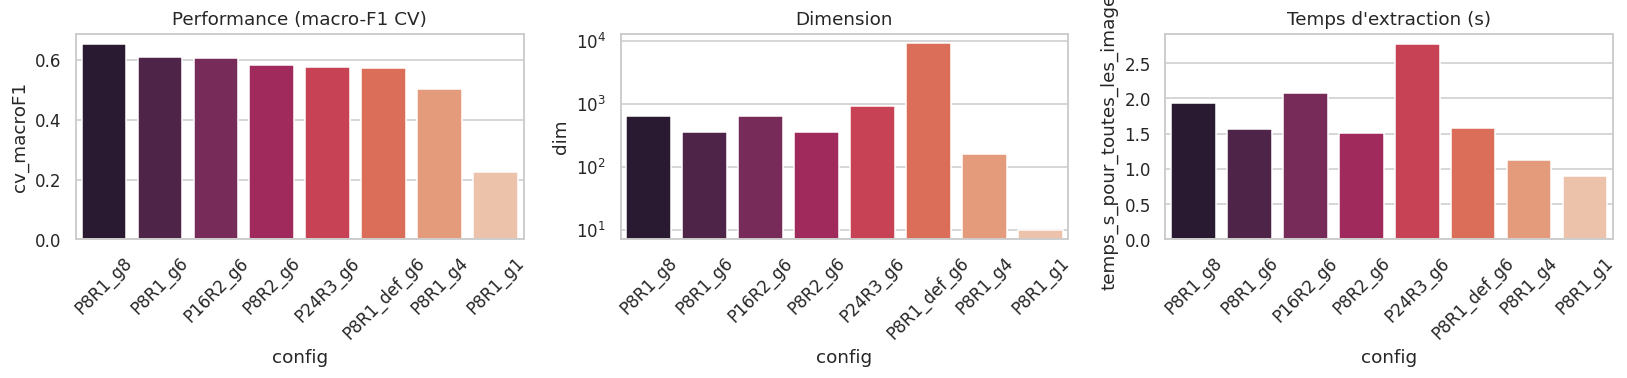

In [17]:
LBP_CONFIGS = {
    "P8R1_g1":   dict(P=8,  R=1, method="uniform", grid=(1, 1)),
    "P8R1_g4":   dict(P=8,  R=1, method="uniform", grid=(4, 4)),
    "P8R1_g6":   dict(P=8,  R=1, method="uniform", grid=(6, 6)),
    "P8R1_g8":   dict(P=8,  R=1, method="uniform", grid=(8, 8)),
    "P8R2_g6":   dict(P=8,  R=2, method="uniform", grid=(6, 6)),
    "P16R2_g6":  dict(P=16, R=2, method="uniform", grid=(6, 6)),
    "P24R3_g6":  dict(P=24, R=3, method="uniform", grid=(6, 6)),
    "P8R1_def_g6": dict(P=8, R=1, method="default", grid=(6, 6)),
}
if QUICK:
    LBP_CONFIGS = {k: v for k, v in LBP_CONFIGS.items() if k in ("P8R1_g1", "P8R1_g6", "P16R2_g6", "P8R1_g8")}

LBP_X, LBP_TIME, rows = {}, {}, []
for nm, kw in LBP_CONFIGS.items():
    f, t = timeit(extract_lbp, X_img, **kw)
    LBP_X[nm], LBP_TIME[nm] = f, t
    m, s = quick_cv(f)
    rows.append(dict(config=nm, P=kw["P"], R=kw["R"], methode=kw["method"], grille=f"{kw['grid'][0]}x{kw['grid'][1]}",
                     dim=f.shape[1], temps_s_pour_toutes_les_images=round(t, 2), cv_macroF1=round(m, 4), cv_std=round(s, 4)))
lbp_study = pd.DataFrame(rows).sort_values("cv_macroF1", ascending=False)
display(lbp_study)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.barplot(data=lbp_study, x="config", y="cv_macroF1", ax=ax[0], palette="rocket"); ax[0].set_title("Performance (macro-F1 CV)")
sns.barplot(data=lbp_study, x="config", y="dim", ax=ax[1], palette="rocket"); ax[1].set_yscale("log"); ax[1].set_title("Dimension")
sns.barplot(data=lbp_study, x="config", y="temps_s_pour_toutes_les_images", ax=ax[2], palette="rocket"); ax[2].set_title("Temps d'extraction (s)")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

Configurations LBP retenues : ['P8R1_g8', 'P8R1_g6']
[LBP|P8R1_g8                            | SVM] CV macro-F1 = 0.672 ± 0.048 | test macro-F1 = 0.661 | acc = 0.726 | 15s
[LBP|P8R1_g8                            | RF ] CV macro-F1 = 0.415 ± 0.028 | test macro-F1 = 0.428 | acc = 0.602 | 52s
[LBP|P8R1_g8                            | XGB] CV macro-F1 = 0.606 ± 0.025 | test macro-F1 = 0.645 | acc = 0.715 | 40s
[LBP|P8R1_g6                            | SVM] CV macro-F1 = 0.618 ± 0.055 | test macro-F1 = 0.631 | acc = 0.672 | 8s
[LBP|P8R1_g6                            | RF ] CV macro-F1 = 0.378 ± 0.035 | test macro-F1 = 0.352 | acc = 0.511 | 46s
[LBP|P8R1_g6                            | XGB] CV macro-F1 = 0.552 ± 0.031 | test macro-F1 = 0.585 | acc = 0.634 | 22s


,representation,classifier,n_features,best_params,cv_f1_mean,cv_f1_std,test_macro_f1,test_accuracy,refit_s,pred_ms_img
6,LBP|P8R1_g8,SVM,640,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.6723,0.0476,0.6613,0.7258,0.5798,0.6573
7,LBP|P8R1_g8,RF,640,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",0.4145,0.0285,0.4284,0.6022,1.9912,0.0646
8,LBP|P8R1_g8,XGB,640,"{'subsample': 0.7, 'n_estimators': 200, 'max_d...",0.6056,0.0248,0.6453,0.7151,3.5692,0.0189
9,LBP|P8R1_g6,SVM,360,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.6184,0.0552,0.6306,0.6720,0.2712,0.4031
10,LBP|P8R1_g6,RF,360,"{'n_estimators': 400, 'min_samples_leaf': 2, '...",0.3779,0.0354,0.3524,0.5108,5.8197,0.1084
11,LBP|P8R1_g6,XGB,360,"{'subsample': 1.0, 'n_estimators': 100, 'max_d...",0.5518,0.0313,0.5849,0.6344,0.8404,0.0111



=> Meilleure combinaison LBP (validation) : P8R1_g8 + SVM (CV macro-F1 = 0.672)


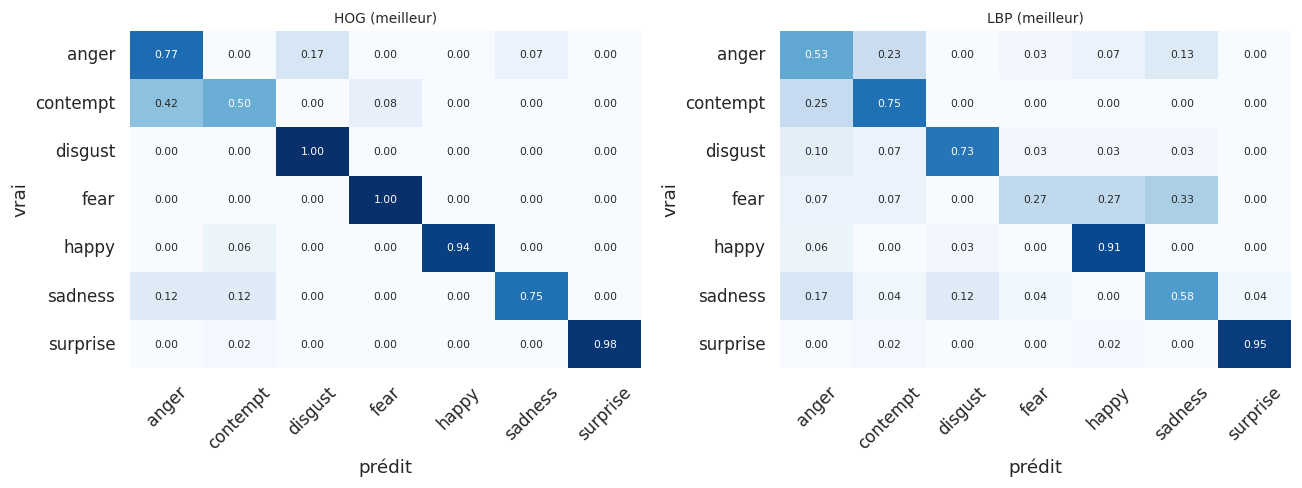

Confusions HOG : [('contempt', 'anger', np.float64(0.42)), ('anger', 'disgust', np.float64(0.17)), ('sadness', 'anger', np.float64(0.12)), ('sadness', 'contempt', np.float64(0.12))]
Confusions LBP : [('fear', 'sadness', np.float64(0.33)), ('fear', 'happy', np.float64(0.27)), ('contempt', 'anger', np.float64(0.25)), ('anger', 'contempt', np.float64(0.23))]
Accord HOG/LBP sur le test : 72.6 % des images ont la même prédiction


In [18]:
top_lbp = lbp_study.config.head(2).tolist()
print("Configurations LBP retenues :", top_lbp)
for nm in top_lbp:
    run_experiment(f"LBP|{nm}", LBP_X[nm], extract_time=LBP_TIME[nm])
lbp_res = results_df().query("representation.str.startswith('LBP')", engine="python")
display(lbp_res[["representation", "classifier", "n_features", "best_params", "cv_f1_mean", "cv_f1_std",
                 "test_macro_f1", "test_accuracy", "refit_s", "pred_ms_img"]].round(4))
b = best_row("LBP"); LBP_BEST_CFG = b.representation.split("|")[1]; LBP_BEST_CLF = b.classifier
print(f"\n=> Meilleure combinaison LBP (validation) : {LBP_BEST_CFG} + {LBP_BEST_CLF} (CV macro-F1 = {b.cv_f1_mean:.3f})")

hb = MODELS[(f"HOG|{HOG_BEST_CFG}", HOG_BEST_CLF)]["pred"]; lb = MODELS[(f"LBP|{LBP_BEST_CFG}", LBP_BEST_CLF)]["pred"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
plot_cm(ax[0], y_te, hb, "HOG (meilleur)"); plot_cm(ax[1], y_te, lb, "LBP (meilleur)"); plt.tight_layout(); plt.show()
print("Confusions HOG :", [(a, c, round(v, 2)) for a, c, v in top_confusions(y_te, hb)])
print("Confusions LBP :", [(a, c, round(v, 2)) for a, c, v in top_confusions(y_te, lb)])
print("Accord HOG/LBP sur le test : %.1f %% des images ont la même prédiction" % (100 * np.mean(hb == lb)))

### Réponses — Partie 4

1. **Information décrite.** La **micro-texture locale** : motifs de bords, coins, points et zones plates. Sur un visage, les plis (front, nasogéniens), la forme de la bouche/paupières et la rugosité de la peau modifient la distribution des motifs.
2. **Rayon et voisins.** Un petit rayon (R=1, P=8) capte la micro-texture fine ; un grand rayon (R=2–3, P=16–24) capte des structures plus larges (plis) mais devient plus sensible au flou/interpolation et augmente la dimension (`P+2` bins par cellule en motifs uniformes). Voir le tableau `lbp_study` et les codes LBP affichés.
3. **Perte avec un histogramme global.** L'histogramme **global** supprime toute information spatiale : on sait *quels* motifs existent mais pas *où* (bouche vs sourcils). La grille d'histogrammes par cellules restaure la localisation au prix d'une dimension plus grande (comparer `g1` à `g4/g6/g8`).
4. **Meilleur classifieur.** Voir le tableau (CV macro-F1) ; mêmes remarques que pour HOG.
5. **Sensibilité aux variations.** LBP est invariant à toute transformation monotone des niveaux de gris (éclairage global) mais sensible au bruit, au flou et à de petits décalages de cadrage ; HOG est invariant au gain local via la normalisation par bloc. Sur CK+ (éclairage contrôlé) ces avantages sont modestes : la comparaison empirique est donnée par les scores ci-dessus.
6. **Mêmes confusions ?** La comparaison des confusions principales et le taux d'accord HOG/LBP ci-dessus répondent empiriquement ; un accord incomplet signale une **complémentarité** exploitable par la fusion.

# Partie 5 — Fusion des caractéristiques HOG et LBP

**Méthode (fusion précoce / *feature-level*).** Concaténation des meilleures configurations HOG et LBP. Les deux familles n'ont ni la même dimension ni la même échelle (HOG ≈ milliers de dimensions normalisées L2-Hys, LBP ≈ centaines d'histogrammes Hellinger) : sans précaution, le bloc le plus grand dominerait distances et marges d'un SVM.
`BlockScaler` : (i) standardisation par colonne avec les **statistiques d'apprentissage** (dans le pipeline, donc sans fuite), (ii) pondération de chaque bloc par `1/√dim_bloc` pour que chaque famille contribue avec la même énergie totale.

HOG ppc6_o9_b3 (2916 dim) + LBP P8R1_g8 (640 dim) -> fusion : 3556 dim
[FUSION|HOG+LBP                         | SVM] CV macro-F1 = 0.838 ± 0.074 | test macro-F1 = 0.876 | acc = 0.887 | 92s
[FUSION|HOG+LBP                         | RF ] CV macro-F1 = 0.605 ± 0.045 | test macro-F1 = 0.654 | acc = 0.731 | 449s
[FUSION|HOG+LBP                         | XGB] CV macro-F1 = 0.698 ± 0.023 | test macro-F1 = 0.686 | acc = 0.763 | 355s


,representation,classifier,n_features,cv_f1_mean,cv_f1_std,test_macro_f1,test_balanced_acc,test_accuracy,extract_s,refit_s,pred_ms_img
0,HOG|ppc6_o9_b3,SVM,2916,0.8317,0.0352,0.8457,0.8475,0.8817,1.9988,3.7062,3.6639
1,HOG|ppc6_o9_b3,RF,2916,0.5996,0.0512,0.6676,0.6692,0.7419,1.9988,89.8104,0.1034
2,HOG|ppc6_o9_b3,XGB,2916,0.6932,0.0210,0.6655,0.6780,0.7634,1.9988,13.5298,0.0216
6,LBP|P8R1_g8,SVM,640,0.6723,0.0476,0.6613,0.6754,0.7258,1.9420,0.5798,0.6573
7,LBP|P8R1_g8,RF,640,0.4145,0.0285,0.4284,0.4778,0.6022,1.9420,1.9912,0.0646
8,LBP|P8R1_g8,XGB,640,0.6056,0.0248,0.6453,0.6406,0.7151,1.9420,3.5692,0.0189
12,FUSION|HOG+LBP,SVM,3556,0.8382,0.0737,0.8756,0.8716,0.8871,3.9408,3.9482,4.5755
13,FUSION|HOG+LBP,RF,3556,0.6054,0.0452,0.6541,0.6597,0.7312,3.9408,95.6635,0.1007
14,FUSION|HOG+LBP,XGB,3556,0.6984,0.0234,0.6859,0.6909,0.7634,3.9408,14.9229,0.0235


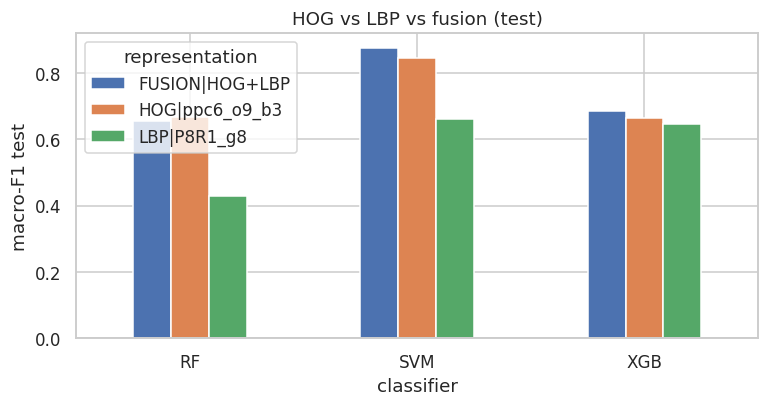

,HOG,LBP,FUSION,Δ fusion - meilleur seul
anger,0.754,0.542,0.667,-0.087
contempt,0.500,0.545,0.818,0.273
disgust,0.923,0.786,0.915,-0.008
fear,0.968,0.364,0.933,-0.034
happy,0.969,0.845,1.000,0.031
sadness,0.818,0.583,0.808,-0.010
surprise,0.988,0.964,0.988,0.000


In [19]:
X_hog_b, X_lbp_b = HOG_X[HOG_BEST_CFG], LBP_X[LBP_BEST_CFG]
dh, dl = X_hog_b.shape[1], X_lbp_b.shape[1]
X_fus = np.hstack([X_hog_b, X_lbp_b]); BLK_FUS = [(0, dh), (dh, dh + dl)]
t_fus = HOG_TIME[HOG_BEST_CFG] + LBP_TIME[LBP_BEST_CFG]
print(f"HOG {HOG_BEST_CFG} ({dh} dim) + LBP {LBP_BEST_CFG} ({dl} dim) -> fusion : {X_fus.shape[1]} dim")
run_experiment("FUSION|HOG+LBP", X_fus, blocks=BLK_FUS, extract_time=t_fus)

# les représentations HOG seul / LBP seul ont déjà été optimisées dans les MÊMES conditions (mêmes plis, métrique, pondération)
cmp5 = results_df()
cmp5 = cmp5[cmp5.representation.isin([f"HOG|{HOG_BEST_CFG}", f"LBP|{LBP_BEST_CFG}", "FUSION|HOG+LBP"])]
display(cmp5[["representation", "classifier", "n_features", "cv_f1_mean", "cv_f1_std", "test_macro_f1", "test_balanced_acc",
              "test_accuracy", "extract_s", "refit_s", "pred_ms_img"]].round(4))

piv = cmp5.pivot_table(index="classifier", columns="representation", values="test_macro_f1")
piv.plot.bar(figsize=(8, 3.6)); plt.ylabel("macro-F1 test"); plt.title("HOG vs LBP vs fusion (test)"); plt.xticks(rotation=0); plt.show()

# effet par classe (meilleur modèle de chaque représentation)
def best_pred(rep):
    d = results_df(); d = d[d.representation == rep].sort_values("cv_f1_mean", ascending=False).iloc[0]
    return MODELS[(rep, d.classifier)]["pred"], d.classifier
rows = {}
for rep in [f"HOG|{HOG_BEST_CFG}", f"LBP|{LBP_BEST_CFG}", "FUSION|HOG+LBP"]:
    p, _ = best_pred(rep); rows[rep.split("|")[0]] = f1_score(y_te, p, average=None, labels=range(len(CLASSES)), zero_division=0)
perclass = pd.DataFrame(rows, index=CLASSES); perclass["Δ fusion - meilleur seul"] = perclass["FUSION"] - perclass[["HOG", "LBP"]].max(1)
display(perclass.round(3))

### Réponses — Partie 5

1. **Complémentarité.** HOG décrit la **forme** (orientation des contours) ; LBP la **texture** locale (plis, micro-motifs). Ce sont deux vues partiellement décorrélées du même visage ; l'accord partiel de leurs prédictions (Partie 4) en est un indice.
2. **Toutes les métriques ?** Comparer dans le tableau CV et test : une amélioration en macro-F1 CV n'implique pas une amélioration sur toutes les métriques du test (le test est petit : quelques images décalent le score).
3. **Toutes les classes ?** Voir la colonne « Δ fusion − meilleur seul » : en général, la fusion aide certaines classes et peut en pénaliser d'autres.
4. **Dimension et temps.** La dimension est la somme des deux blocs ; le temps d'extraction s'additionne ; entraînement et prédiction augmentent (colonnes `extract_s`, `refit_s`, `pred_ms_img`).
5. **Plus grand = meilleur ?** Non : avec peu de sujets, ajouter des dimensions redondantes augmente la variance (malédiction de la dimension). C'est la motivation de la Partie 6.

# Partie 6 — Sélection de caractéristiques

**Méthode choisie : filtre ANOVA `SelectKBest(f_classif)`** placé **dans le Pipeline**, donc réappris sur chaque pli d'apprentissage.
- *Ce qu'il mesure* : le rapport (variance inter-classes)/(variance intra-classes) de chaque caractéristique (statistique F de l'ANOVA à un facteur) : une caractéristique est retenue si sa moyenne diffère nettement d'une émotion à l'autre.
- *Pourquoi ici* : rapide (milliers de dimensions), supervisé, indépendant du classifieur (comparaison équitable SVM/RF/XGB), invariant à l'échelle de chaque colonne, sans paramètre sauf `k`. Limite : univarié (ignore les interactions entre caractéristiques, mais les blocs HOG/LBP voisins étant redondants, la redondance est gérée en partie par le choix de `k`).
- *Choix de `k`* : courbe macro-F1(k) en CV groupée sur l'apprentissage ; règle de **l'erreur standard** : plus petit `k` dont le score est à ≤ 1 erreur standard du meilleur.

k* (règle 1-SE) = 800 sur 3556 caractéristiques | meilleur k brut = 800


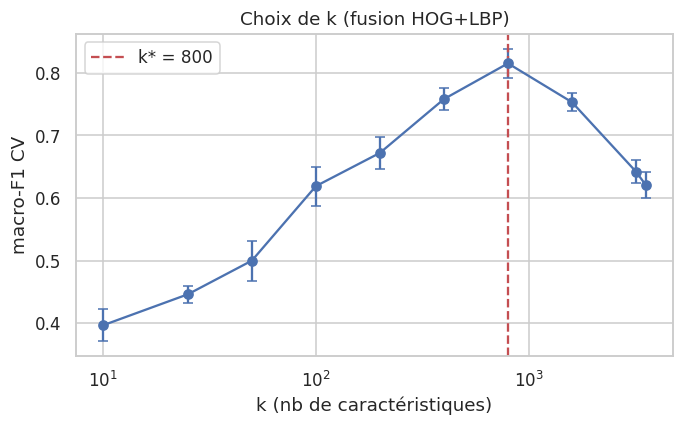

,k,mean,std,se
0,10,0.3969,0.0569,0.0254
1,25,0.4462,0.0300,0.0134
2,50,0.5000,0.0714,0.0319
3,100,0.6189,0.0693,0.0310
4,200,0.6719,0.0575,0.0257
5,400,0.7578,0.0393,0.0176
6,800,0.8148,0.0529,0.0237
7,1600,0.7528,0.0320,0.0143
8,3200,0.6420,0.0405,0.0181
9,3556,0.6206,0.0467,0.0209


In [20]:
def choose_k(Xall, blocks=None, ks=None, verbose=True):
    """Courbe CV macro-F1 en fonction de k (sélection apprise DANS chaque pli), règle de l'erreur standard."""
    d = Xall.shape[1]
    ks = ks or [k for k in [10, 25, 50, 100, 200, 400, 800, 1600, 3200] if k < d] + [d]
    rows = []
    for k in ks:
        pipe = Pipeline([("prep", BlockScaler(blocks=blocks)), ("sel", SelectKBest(f_classif, k=k)),
                         ("clf", SVC(kernel="rbf", C=10, class_weight="balanced"))])
        s = cross_val_score(pipe, Xall[tr_idx], y_tr, cv=cv_splits, scoring="f1_macro", n_jobs=N_JOBS)
        rows.append(dict(k=k, mean=s.mean(), std=s.std(), se=s.std() / np.sqrt(len(s))))
    curve = pd.DataFrame(rows)
    ib = curve["mean"].idxmax(); thr = curve.loc[ib, "mean"] - curve.loc[ib, "se"]
    k_star = int(curve[curve["mean"] >= thr]["k"].min())
    if verbose:
        print(f"k* (règle 1-SE) = {k_star} sur {d} caractéristiques | meilleur k brut = {int(curve.loc[ib, 'k'])}")
    return k_star, curve

K_FUS, curve_fus = choose_k(X_fus, BLK_FUS)
plt.figure(figsize=(7, 3.8))
plt.errorbar(curve_fus.k, curve_fus["mean"], yerr=curve_fus.se, marker="o", capsize=3)
plt.axvline(K_FUS, color="r", ls="--", label=f"k* = {K_FUS}"); plt.xscale("log"); plt.xlabel("k (nb de caractéristiques)")
plt.ylabel("macro-F1 CV"); plt.title("Choix de k (fusion HOG+LBP)"); plt.legend(); plt.show()
display(curve_fus.round(4))

In [21]:
# ----- stabilité de la sélection entre plis + composition des caractéristiques retenues
def selection_stability(Xall, blocks, k, names):
    sets = []
    for a, b in cv_splits:
        sc = BlockScaler(blocks=blocks).fit(Xall[tr_idx][a])
        sel = SelectKBest(f_classif, k=k).fit(sc.transform(Xall[tr_idx][a]), y_tr[a]); sets.append(set(np.where(sel.get_support())[0]))
    jac = np.mean([len(s1 & s2) / len(s1 | s2) for s1, s2 in itertools.combinations(sets, 2)])
    sc = BlockScaler(blocks=blocks).fit(Xall[tr_idx]); sel = SelectKBest(f_classif, k=k).fit(sc.transform(Xall[tr_idx]), y_tr)
    idx = np.where(sel.get_support())[0]
    comp = {nm: int(((idx >= a) & (idx < b)).sum()) for nm, (a, b) in zip(names, blocks)}
    return jac, comp

jac, comp = selection_stability(X_fus, BLK_FUS, K_FUS, ["HOG", "LBP"])
print(f"Stabilité (indice de Jaccard moyen entre plis) = {jac:.2f}")
print("Composition des k caractéristiques retenues :", comp, "| répartition attendue au hasard :", {"HOG": round(K_FUS * dh / (dh + dl)), "LBP": round(K_FUS * dl / (dh + dl))})

run_experiment(f"SELECT|HOG+LBP|k{K_FUS}", X_fus, blocks=BLK_FUS, sel_k=K_FUS, extract_time=t_fus)
cmp6 = results_df(); cmp6 = cmp6[cmp6.representation.isin(["FUSION|HOG+LBP", f"SELECT|HOG+LBP|k{K_FUS}"])]
display(cmp6[["representation", "classifier", "n_used", "cv_f1_mean", "cv_f1_std", "test_macro_f1", "test_accuracy", "refit_s", "pred_ms_img"]].round(4))

Stabilité (indice de Jaccard moyen entre plis) = 0.81
Composition des k caractéristiques retenues : {'HOG': 766, 'LBP': 34} | répartition attendue au hasard : {'HOG': 656, 'LBP': 144}
[SELECT|HOG+LBP|k800                    | SVM] CV macro-F1 = 0.815 ± 0.053 | test macro-F1 = 0.828 | acc = 0.844 | 17s
[SELECT|HOG+LBP|k800                    | RF ] CV macro-F1 = 0.649 ± 0.068 | test macro-F1 = 0.634 | acc = 0.742 | 119s
[SELECT|HOG+LBP|k800                    | XGB] CV macro-F1 = 0.754 ± 0.037 | test macro-F1 = 0.691 | acc = 0.763 | 60s


,representation,classifier,n_used,cv_f1_mean,cv_f1_std,test_macro_f1,test_accuracy,refit_s,pred_ms_img
12,FUSION|HOG+LBP,SVM,3556,0.8382,0.0737,0.8756,0.8871,3.9482,4.5755
13,FUSION|HOG+LBP,RF,3556,0.6054,0.0452,0.6541,0.7312,95.6635,0.1007
14,FUSION|HOG+LBP,XGB,3556,0.6984,0.0234,0.6859,0.7634,14.9229,0.0235
15,SELECT|HOG+LBP|k800,SVM,800,0.8154,0.0527,0.8277,0.8441,0.7269,0.7739
16,SELECT|HOG+LBP|k800,RF,800,0.6487,0.0678,0.6341,0.7419,3.8994,0.1143
17,SELECT|HOG+LBP|k800,XGB,800,0.7544,0.0373,0.6909,0.7634,2.7346,0.0183


### Réponses — Partie 6

1. **Choix de la méthode.** Voir l'encadré d'introduction : filtre ANOVA rapide, supervisé, indépendant du modèle, scalable à des milliers de dimensions et intégrable dans un `Pipeline`.
2. **Choix de k.** Par la courbe macro-F1(k) en CV groupée sur l'apprentissage et la règle de l'erreur standard (le plus petit k statistiquement équivalent au meilleur).
3. **Moment de l'apprentissage de la sélection.** À l'intérieur de **chaque pli** d'apprentissage (et une dernière fois sur tout l'apprentissage pour le modèle final) ; jamais avec les images de validation ni de test.
4. **Généralisation ou rapidité ?** Comparer CV et test entre fusion complète et sélection : un gain de macro-F1 indique un effet de régularisation ; des scores équivalents avec moins de dimensions indiquent surtout un gain de rapidité (colonnes `refit_s`, `pred_ms_img`).
5. **Risques si la sélection précède la validation.** Une sélection supervisée faite sur **toutes** les données « voit » les étiquettes des plis de validation (et du test) : elle choisit les caractéristiques qui séparent *ces* images, ce qui gonfle fortement les scores (fuite de sélection), d'autant plus que `d ≫ n`.
6. **Meilleur classifieur ?** Lire le tableau : comparer le classement par CV macro-F1 avant/après sélection.

# Partie 7 — Comparaison intermédiaire du TP1 (HOG / LBP / fusion / sélection)

Récapitulatif des pipelines du TP1 avant d'ajouter les landmarks (Partie 8). La comparaison **finale**, avec les landmarks, les matrices de confusion et la discussion complète, est en Partie 9.

In [22]:
tp1 = results_df()
tp1 = tp1[tp1.representation.str.match(r"^(HOG|LBP)\||^FUSION\|HOG\+LBP$|^SELECT\|HOG\+LBP\|")]
display(tp1.sort_values("cv_f1_mean", ascending=False)[["representation", "classifier", "n_used", "best_params", "cv_f1_mean", "cv_f1_std",
                                                         "test_macro_f1", "test_balanced_acc", "test_accuracy", "extract_s", "refit_s", "pred_ms_img"]].round(4))

,representation,classifier,n_used,best_params,cv_f1_mean,cv_f1_std,test_macro_f1,test_balanced_acc,test_accuracy,extract_s,refit_s,pred_ms_img
12,FUSION|HOG+LBP,SVM,3556,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.8382,0.0737,0.8756,0.8716,0.8871,3.9408,3.9482,4.5755
0,HOG|ppc6_o9_b3,SVM,2916,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.8317,0.0352,0.8457,0.8475,0.8817,1.9988,3.7062,3.6639
3,HOG|ppc6_o9,SVM,1764,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.8175,0.0416,0.8165,0.8215,0.8710,2.5396,1.7716,1.7934
15,SELECT|HOG+LBP|k800,SVM,800,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.8154,0.0527,0.8277,0.8282,0.8441,3.9408,0.7269,0.7739
17,SELECT|HOG+LBP|k800,XGB,800,"{'subsample': 1.0, 'n_estimators': 100, 'max_d...",0.7544,0.0373,0.6909,0.6814,0.7634,3.9408,2.7346,0.0183
5,HOG|ppc6_o9,XGB,1764,"{'subsample': 1.0, 'n_estimators': 100, 'max_d...",0.7013,0.0128,0.6929,0.6992,0.7796,2.5396,7.1019,0.0167
14,FUSION|HOG+LBP,XGB,3556,"{'subsample': 0.7, 'n_estimators': 100, 'max_d...",0.6984,0.0234,0.6859,0.6909,0.7634,3.9408,14.9229,0.0235
2,HOG|ppc6_o9_b3,XGB,2916,"{'subsample': 1.0, 'n_estimators': 100, 'max_d...",0.6932,0.0210,0.6655,0.6780,0.7634,1.9988,13.5298,0.0216
6,LBP|P8R1_g8,SVM,640,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.6723,0.0476,0.6613,0.6754,0.7258,1.9420,0.5798,0.6573
16,SELECT|HOG+LBP|k800,RF,800,"{'n_estimators': 400, 'min_samples_leaf': 2, '...",0.6487,0.0678,0.6341,0.6488,0.7419,3.9408,3.8994,0.1143


# Partie 8 — Suite du TP : Facial Landmarks (LUVLi / dlib), état de l'art et fusion

## 8.1 Petit état de l'art (landmarks pour la reconnaissance d'expressions)

Recherche bibliographique effectuée le 20/10/2026 (sources en fin de section). Ce qui en ressort :

| # | Travail | Idée retenue | Ce que j'en reprends |
|---|---|---|---|
| 1 | **Lucey et al., CK+, CVPRW 2010** | Le dataset CK+ est fourni avec **68 landmarks AAM** par image et des séquences allant du visage neutre au pic d'expression. | Le format à 68 points (schéma iBUG) est un standard pour CK+ ; la limite « pas de frame neutre » dans la version Kaggle empêche d'utiliser des *déplacements* neutre→pic. |
| 2 | **Kumar, Marks, Mou et al., LUVLi, CVPR 2020** | Réseau d'alignement qui estime **simultanément la position, l'incertitude et la visibilité** de chaque landmark (68 points). L'incertitude permet d'identifier les images sur lesquelles l'alignement échoue. | **Idée centrale :** utiliser l'**incertitude des landmarks comme descripteur de fiabilité** (et pour détecter les images mal alignées), pas seulement leurs positions. |
| 3 | **Distances entre paires de landmarks + SVM** (arXiv:1701.01879) | Deux combinaisons des 68 landmarks produisent **2278 paires** ; les variations (distances horizontales/verticales) servent de caractéristiques à un SVM multi-classes sur CK+. | Famille **« distances denses »** (toutes les paires) comme caractéristique candidate, et sélection derrière. |
| 4 | **Discriminative geometric features (triangles)** — suivi de landmarks + AdaBoost + SVM (IJMUE) | Caractéristiques géométriques basées sur des **triangles** formés de landmarks, sélectionnées par AdaBoost ; ~97,8 % sur CK+ (protocole de la publication). | **Aires/angles de triangles** (yeux, sourcils, bouche) + étape de **sélection** de caractéristiques. |
| 5 | **Liu, Cheng & Lee, GA-SVM, IEEE Sensors J. 2020** | Deux nouvelles caractéristiques : **courbure de landmark** et **landmark vectorisé**, calculées par composante musculaire (régions du visage) ; SVM + algorithme génétique ; ≥ 95 % sur CK+/MUG. | **Courbure** des courbes sourcils / lèvres / mâchoire et description **région par région**. |
| 6 | **Happy & Routray, 2015** (arXiv:1505.04030) | **Patches faciaux actifs** localisés grâce aux landmarks (zones qui bougent) ; descripteurs **PHOG + LBP** concaténés, SVM. Moins de calcul et moins de sur-apprentissage qu'un descripteur sur tout le visage. | **Descripteurs d'apparence calculés sur des patches guidés par les landmarks** (yeux+sourcils, nez, bouche). |
| 7 | **Liu, Li, Ma, Song, Sensors 2017** | **Fusion LBP + HOG** sur des zones saillantes du visage, réduction par PCA, correction gamma sur LBP. | Justifie la fusion HOG+LBP du TP et la **normalisation des blocs** avant fusion. |
| 8 | **Fusion géométrie + apparence (peak-frame)** — *Facial expression recognition based on hybrid geometry-appearance and dynamic-still feature fusion* | Landmarks du pic = caractéristique géométrique, fusionnée avec de l'apparence (LBP-TOP). | Fusion **géométrie + apparence** comme principe général. |
| 9 | **GLaRE (arXiv:2508.20579)**, enquêtes sur les **GNN pour FER** (Gueuret et al., CBMI 2024) | Les landmarks forment naturellement un **graphe** (régions du visage) ; les GCN/GAT exploitent les relations locales/globales. | Pistes d'amélioration (hors périmètre « classique » du TP). |
| 10 | **Kazemi & Sullivan, CVPR 2014** (détecteur de landmarks de **dlib**, 68 points) | Régression par **ensemble d'arbres de régression en cascade**, très rapide. | Méthode de repli utilisée si LUVLi n'est pas disponible. |

### Idée retenue (synthèse) : **fusion hybride guidée par les landmarks et consciente de l'incertitude**
Je combine trois idées issues de la littérature :
1. **(LUVLi, #2)** → un descripteur de **fiabilité** : l'incertitude par landmark, résumée par région (sourcils, yeux, nez, bouche, mâchoire). Si LUVLi n'est pas disponible, l'incertitude est estimée par **dispersion des prédictions sur des vues augmentées** (*test-time augmentation*, déplacements/rotations/échelles légers) — même principe (variance de la position prédite), moins précis.
2. **(Happy & Routray #6, Liu #7)** → **patchs d'apparence guidés par les landmarks** : HOG+LBP calculés uniquement sur les zones qui portent l'expression (yeux+sourcils, nez, bouche) plutôt que sur une grille fixe.
3. **(#3, #4, #5)** → une **géométrie compacte et interprétable** : distances normalisées par la distance inter-oculaire, angles, ouverture des yeux/bouche, courbures et aires de triangles — comparée à la version « toutes les paires » (2278 distances) et aux simples coordonnées alignées.

Puis fusion précoce avec les descripteurs HOG/LBP du TP1 (`BlockScaler`) + sélection de caractéristiques, et **fusion tardive** (moyenne de probabilités) comme point de comparaison.

**Sources** : Lucey et al. 2010 (IEEE CVPRW, doi:10.1109/CVPRW.2010.5543262) · Kumar et al. 2020 (CVPR, arXiv:2004.02980) · arXiv:1701.01879 · *Recognition of Facial Expressions Based on Tracking and Selection of Discriminative Geometric Features* (IJMUE) · Liu, Cheng, Lee 2020 (IEEE Sensors J., doi:10.1109/JSEN.2020.3028075) · Happy & Routray 2015 (arXiv:1505.04030) · Liu et al. 2017 (Sensors 17(4):712) · arXiv:2508.20579 (GLaRE) · Gueuret, Sellami, Djeraba 2024 (CBMI, hal-04768316) · Kazemi & Sullivan 2014 (CVPR).

## 8.2 Détection des 68 landmarks

**Stratégie (par ordre de préférence, choisie automatiquement) :**
1. **LUVLi** (Kumar et al., CVPR 2020) si une fonction `luvli_predict` est fournie (voir ci-dessous). Le code officiel est distribué par MERL sous licence de recherche (dépôt `merlresearch/LUVLi`, poids pré-entraînés sur Zenodo `10.5281/zenodo.10870537`, ~565 Mo) : il faut accepter la licence et le cloner soi-même ; je n'ai pas pu l'exécuter dans mon environnement, donc **l'adaptateur est à brancher** par vous (3 lignes, contrat ci-dessous). LUVLi fournit nativement les 68 points **et** leur incertitude.
2. **dlib** (Kazemi & Sullivan, 68 points) : `shape_predictor_68_face_landmarks.dat` téléchargé automatiquement.
3. **FAN** (`face-alignment`, PyTorch) en dernier recours.

Les images de `CK+48` sont des visages **recadrés de 48×48 px** : elles sont agrandies à 192×192 (×4, interpolation cubique) et la boîte englobante du visage est l'image entière (un détecteur de visages échouerait sur des crops aussi serrés). Pour toutes les méthodes, **l'incertitude est aussi estimée par TTA** (`LM_TTA` vues : rotation ±6°, échelle ±5 %, translation ±4 %) ; les landmarks finaux sont la **moyenne** des vues (plus stable qu'une seule prédiction).

In [23]:
# ====== Branchement optionnel de LUVLi ======================================================
# Contrat attendu :   luvli_predict(gray_uint8_HxW) -> (landmarks (68,2) en pixels de l'image reçue, sigma (68,) ou None)
# 1) git clone https://github.com/merlresearch/LUVLi  (licence MERL de recherche, à accepter)
# 2) télécharger les poids (Zenodo 10.5281/zenodo.10870537) comme décrit dans le README du dépôt
# 3) écrire la fonction ci-dessous avec le code d'inférence du dépôt, par ex. :
#
# def luvli_predict(gray):
#     ...  # prétraitement + forward LUVLi du dépôt officiel
#     return lm_xy, sigma
#
luvli_predict = None      # laisser None pour utiliser dlib (ou FAN)

LM_BACKEND_PREF = "auto"  # "auto" | "luvli" | "dlib" | "fan"
UP = 192                  # taille d'agrandissement avant détection

In [24]:
import bz2, urllib.request

def init_dlib():
    try:
        import dlib
    except ImportError:
        try: ensure("dlib-bin", "dlib")
        except Exception: ensure("dlib", "dlib")
        import dlib
    fn = Path("shape_predictor_68_face_landmarks.dat")
    if not fn.exists():
        print("Téléchargement du modèle dlib (≈ 100 Mo)...")
        data = urllib.request.urlopen("http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2", timeout=120).read()
        fn.write_bytes(bz2.decompress(data))
    sp = dlib.shape_predictor(str(fn))
    def predict(gray):
        H, W = gray.shape
        rect = dlib.rectangle(int(.02 * W), int(.02 * H), int(.98 * W) - 1, int(.98 * H) - 1)   # visage déjà recadré
        sh = sp(gray, rect)
        return np.array([[p.x, p.y] for p in sh.parts()], dtype=np.float64), None
    return predict

def init_fan():
    ensure("face-alignment", "face_alignment")
    import face_alignment, torch
    lt = getattr(face_alignment.LandmarksType, "TWO_D", None) or face_alignment.LandmarksType._2D
    fa = face_alignment.FaceAlignment(lt, flip_input=False, device="cuda" if torch.cuda.is_available() else "cpu")
    def predict(gray):
        H, W = gray.shape
        out = fa.get_landmarks_from_image(np.dstack([gray] * 3), detected_faces=[[0, 0, W - 1, H - 1]])
        return out[0][:, :2].astype(np.float64), None
    return predict

def get_landmark_predictor(pref=LM_BACKEND_PREF):
    order = {"auto": ["luvli", "dlib", "fan"]}.get(pref, [pref])
    for b in order:
        try:
            if b == "luvli":
                if callable(luvli_predict): return "LUVLi", luvli_predict
                if pref == "luvli": raise RuntimeError("luvli_predict n'est pas défini")
                continue
            if b == "dlib": return "dlib", init_dlib()
            if b == "fan": return "FAN", init_fan()
        except Exception as e:
            print(f"[backend {b}] indisponible : {type(e).__name__}: {e}")
    raise RuntimeError("Aucun détecteur de landmarks disponible")

LM_BACKEND, lm_predict = get_landmark_predictor()
print("Détecteur de landmarks utilisé :", LM_BACKEND)

Téléchargement du modèle dlib (≈ 100 Mo)...
Détecteur de landmarks utilisé : dlib


In [25]:
def random_affine(rng, size, rot=6, scale=0.05, shift=0.04):
    a = np.deg2rad(rng.uniform(-rot, rot)); s = 1 + rng.uniform(-scale, scale)
    c = size / 2; tx, ty = rng.uniform(-shift, shift, 2) * size
    M_ = np.array([[s * np.cos(a), -s * np.sin(a), 0], [s * np.sin(a), s * np.cos(a), 0]])
    M_[:, 2] = np.array([c, c]) + [tx, ty] - M_[:, :2] @ np.array([c, c])
    return M_

def detect_with_tta(img48, predict, T=LM_TTA, seed=0):
    """Landmarks moyens + incertitude (écart-type, en pixels de l'image 48x48) par dispersion sur T vues."""
    up = cv2.resize(img48, (UP, UP), interpolation=cv2.INTER_CUBIC)
    r = np.random.default_rng(seed); pts, nat = [], []
    for t in range(T):
        A = np.array([[1, 0, 0], [0, 1, 0]], dtype=np.float64) if t == 0 else random_affine(r, UP)
        w = cv2.warpAffine(up, A, (UP, UP), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        lm, sg = predict(w)
        Ai = cv2.invertAffineTransform(A)
        pts.append(lm @ Ai[:, :2].T + Ai[:, 2])
        if sg is not None: nat.append(np.asarray(sg, dtype=np.float64))
    pts = np.stack(pts) / (UP / IMG)                       # -> repère 48x48
    mean = pts.mean(0)
    std = np.sqrt(((pts - mean) ** 2).sum(-1).mean(0))     # (68,) dispersion radiale
    nat_sig = (np.mean(nat, 0) / (UP / IMG)) if nat else None
    return mean, std, nat_sig

cache = Path(f"landmarks_{LM_BACKEND}_T{LM_TTA}_n{len(X_img)}.npz")
if cache.exists():
    z = np.load(cache, allow_pickle=True); LM_MEAN, LM_STD, LM_NAT = z["mean"], z["std"], (z["nat"] if z["nat"].size > 1 else None)
    print("Landmarks chargés depuis le cache :", cache)
else:
    LM_MEAN, LM_STD, nats, fails = [], [], [], []
    t0 = time.perf_counter()
    for i, im in enumerate(X_img):
        try:
            m_, s_, n_ = detect_with_tta(im, lm_predict, seed=i)
        except Exception as e:
            fails.append(i); m_, s_, n_ = np.full((68, 2), np.nan), np.full(68, np.nan), None
        LM_MEAN.append(m_); LM_STD.append(s_); nats.append(n_)
        if (i + 1) % 200 == 0: print(f"  {i + 1}/{len(X_img)} images ({time.perf_counter() - t0:.0f}s)")
    LM_MEAN, LM_STD = np.stack(LM_MEAN), np.stack(LM_STD)
    LM_NAT = np.stack(nats) if all(n is not None for n in nats) else None
    np.savez(cache, mean=LM_MEAN, std=LM_STD, nat=(LM_NAT if LM_NAT is not None else np.zeros(1)))
    print(f"Détection terminée en {time.perf_counter() - t0:.0f}s | échecs : {len(fails)}")

bad = ~np.isfinite(LM_MEAN).all((1, 2))
print("Images sans landmarks valides :", int(bad.sum()))
if bad.any():                       # imputation par le visage moyen de la même émotion (rare)
    for i in np.where(bad)[0]:
        LM_MEAN[i] = np.nanmean(LM_MEAN[(df.emotion.values == df.emotion.values[i]) & ~bad], 0); LM_STD[i] = np.nanmedian(LM_STD[~bad])

  200/1962 images (3s)
  400/1962 images (5s)
  600/1962 images (8s)
  800/1962 images (10s)
  1000/1962 images (13s)
  1200/1962 images (15s)
  1400/1962 images (18s)
  1600/1962 images (20s)
  1800/1962 images (23s)
Détection terminée en 25s | échecs : 0
Images sans landmarks valides : 0


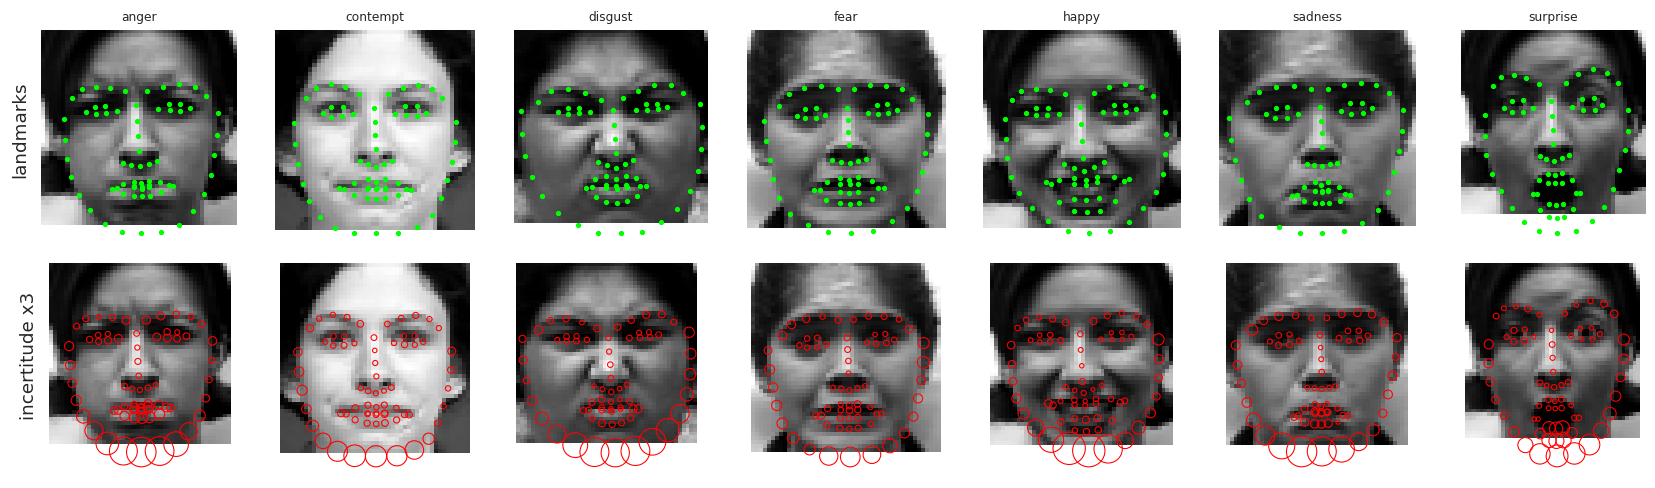

Incertitude moyenne par image (px sur 48x48) : médiane = 0.244, p95 = 0.422


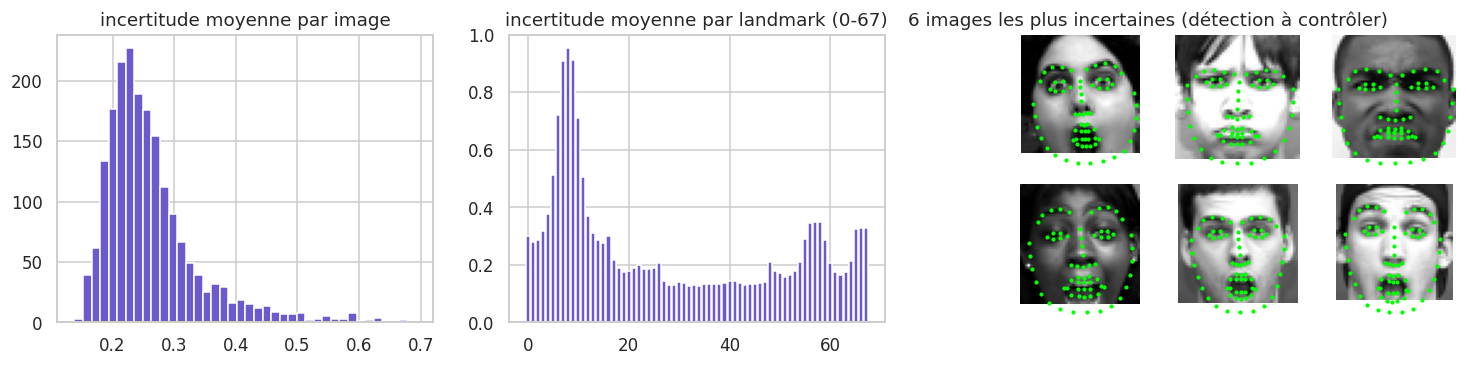

In [26]:
# ----- visualisation : landmarks + incertitude (cercles ∝ dispersion)
fig, axes = plt.subplots(2, len(CLASSES), figsize=(2.2 * len(CLASSES), 4.6))
for k, c in enumerate(CLASSES):
    i = np.where(df.emotion.values == c)[0][0]
    for r in range(2):
        ax = axes[r, k]; ax.imshow(X_img[i], cmap="gray"); ax.axis("off")
        ax.scatter(LM_MEAN[i, :, 0], LM_MEAN[i, :, 1], s=6 if r == 0 else 0, c="lime")
        if r == 1:
            for (x_, y_), s_ in zip(LM_MEAN[i], LM_STD[i]): ax.add_patch(plt.Circle((x_, y_), s_ * 3 + .3, fill=False, color="red", lw=.7))
    axes[0, k].set_title(c, fontsize=8)
axes[0, 0].text(-8, 24, "landmarks", rotation=90, va="center"); axes[1, 0].text(-8, 24, "incertitude x3", rotation=90, va="center")
plt.tight_layout(); plt.show()

img_unc = LM_STD.mean(1)
print(f"Incertitude moyenne par image (px sur 48x48) : médiane = {np.median(img_unc):.3f}, p95 = {np.percentile(img_unc, 95):.3f}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].hist(img_unc, bins=40, color="slateblue"); ax[0].set_title("incertitude moyenne par image")
ax[1].bar(range(68), LM_STD.mean(0), color="slateblue"); ax[1].set_title("incertitude moyenne par landmark (0-67)")
worst = np.argsort(-img_unc)[:6]
ax[2].axis("off"); ax[2].set_title("6 images les plus incertaines (détection à contrôler)")
for k, i in enumerate(worst):
    a = fig.add_axes([0.70 + (k % 3) * 0.095, 0.12 + (k // 3) * 0.40, 0.09, 0.36]); a.imshow(X_img[i], cmap="gray"); a.scatter(*LM_MEAN[i].T, s=3, c="lime"); a.axis("off")
plt.show()

## 8.3 Caractéristiques extraites des landmarks et justification

Toutes les caractéristiques sont calculées après **alignement par similitude** (translation au milieu des yeux, rotation pour mettre la ligne inter-oculaire à l'horizontale, échelle = distance inter-oculaire, IOD) : elles sont donc **invariantes à la position, à l'échelle et à la rotation dans le plan** — indispensable puisque l'expression doit être séparée de la pose/cadrage.

| Famille | Contenu | Justification (littérature) |
|---|---|---|
| **LM-coords** | 136 coordonnées alignées | Représentation de forme brute (« landmark vectorisé », #5) : référence de comparaison. |
| **LM-geo** (compacte, interprétable) | distances normalisées (sourcil–œil, ouverture des yeux/EAR, largeur/ouverture de bouche/MAR, nez–lèvre, coins de bouche–nez/yeux/mâchoire…), **angles** (coins de bouche, pente et arche des sourcils, mâchoire), **hauteur relative des commissures** (sourire), **courbures** (sourcils, lèvres, mâchoire, nez), **aires/circularité** des contours fermés, **aires de triangles** | Mouvements musculaires associés aux AU : sourcils levés/froncés (surprise, colère), yeux ouverts (surprise, peur), commissures relevées (joie), nez plissé et lèvre supérieure relevée (dégoût) ; courbures (#5), triangles (#4), distances (#3). |
| **LM-dense** | 2278 distances entre toutes les paires de landmarks | #3 ; testée avec sélection de caractéristiques. |
| **UNC** (7 dim.) | incertitude moyenne par région (sourcils, yeux, nez, bouche, mâchoire), globale et maximale (normalisée par IOD) | LUVLi (#2) : fiabilité de la détection ; permet au classifieur de pondérer implicitement la géométrie. |
| **REGION** | HOG + LBP sur des patchs **yeux+sourcils, nez, bouche** localisés par les landmarks | #6, #7 : l'apparence là où se produit l'expression. |

*Remarque.* La version Kaggle de CK+ (images 48×48 de pics d'expression) ne contient pas la frame neutre de chaque sujet : on ne peut donc pas utiliser les **déplacements neutre → pic** (#3, #4) ; la géométrie utilisée est **absolue** (normalisée), plus sensible à la morphologie du sujet.

In [27]:
IOD_IDX = dict(jaw=range(0, 17), rbrow=range(17, 22), lbrow=range(22, 27), nose=range(27, 36),
               reye=range(36, 42), leye=range(42, 48), omouth=range(48, 60), imouth=range(60, 68))

def align_landmarks(L):
    re, le = L[:, 36:42].mean(1), L[:, 42:48].mean(1)
    d = le - re; iod = np.linalg.norm(d, axis=1)
    ang = np.arctan2(d[:, 1], d[:, 0]); c, s = np.cos(-ang)[:, None], np.sin(-ang)[:, None]
    Lc = L - ((re + le) / 2)[:, None, :]
    x = Lc[..., 0] * c - Lc[..., 1] * s; yy = Lc[..., 0] * s + Lc[..., 1] * c
    return np.stack([x, yy], -1) / iod[:, None, None], iod

def D(L, a, b): return np.linalg.norm(L[:, a] - L[:, b], axis=1)
def ANG(L, a, b, c):
    v1, v2 = L[:, a] - L[:, b], L[:, c] - L[:, b]
    cs = (v1 * v2).sum(1) / (np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1) + 1e-9)
    return np.degrees(np.arccos(np.clip(cs, -1, 1)))
def TRI(L, a, b, c):
    u, v = L[:, b] - L[:, a], L[:, c] - L[:, a]
    return 0.5 * np.abs(u[:, 0] * v[:, 1] - u[:, 1] * v[:, 0])
def poly_area_perim(L, idx):
    P = L[:, list(idx)]; Q = np.roll(P, -1, axis=1)
    area = 0.5 * np.abs((P[..., 0] * Q[..., 1] - P[..., 1] * Q[..., 0]).sum(1))
    perim = np.linalg.norm(P - Q, axis=2).sum(1)
    return area, perim
def curvature(L, idx):
    """Coefficients (a, b) de l'ajustement y = a x² + b x + c d'une courbe de landmarks : a ≈ courbure."""
    idx = list(idx); out = np.zeros((len(L), 2))
    for i in range(len(L)):
        co = np.polyfit(L[i, idx, 0], L[i, idx, 1], 2); out[i] = co[0], co[1]
    return out

def geo_features(L):
    f, names = [], []
    def add_(nm, v): f.append(np.asarray(v, dtype=np.float64)); names.append(nm)
    # --- distances
    for nm, (a, b) in {"brow_inner_gap": (21, 22), "rbrow_inner_eye": (21, 39), "lbrow_inner_eye": (22, 42),
                       "rbrow_mid_eye": (19, 37), "lbrow_mid_eye": (24, 44), "rbrow_outer_eye": (17, 36), "lbrow_outer_eye": (26, 45),
                       "nose_len": (27, 30), "nostril_w": (31, 35), "nose_lip": (33, 51), "nose_tip_lip": (30, 51),
                       "mouth_w": (48, 54), "mouth_open_out": (51, 57), "mouth_open_in": (62, 66), "mouth_w_in": (60, 64),
                       "upper_lip": (51, 62), "lower_lip": (57, 66),
                       "rcorner_nose": (48, 33), "lcorner_nose": (54, 33), "rcorner_eye": (48, 36), "lcorner_eye": (54, 45),
                       "chin_lip": (8, 57), "chin_nose": (8, 33), "jaw_w": (4, 12),
                       "reye_w": (36, 39), "leye_w": (42, 45)}.items():
        add_("d_" + nm, D(L, a, b))
    # --- ouverture des yeux (EAR) et de la bouche (MAR)
    add_("EAR_r", (D(L, 37, 41) + D(L, 38, 40)) / (2 * D(L, 36, 39) + 1e-9))
    add_("EAR_l", (D(L, 43, 47) + D(L, 44, 46)) / (2 * D(L, 42, 45) + 1e-9))
    add_("MAR", (D(L, 61, 67) + D(L, 62, 66) + D(L, 63, 65)) / (3 * D(L, 60, 64) + 1e-9))
    # --- commissures relativement au centre de la bouche (sourire : valeur positive = commissure relevée)
    yc = (L[:, 51, 1] + L[:, 57, 1]) / 2
    add_("corner_lift_r", yc - L[:, 48, 1]); add_("corner_lift_l", yc - L[:, 54, 1])
    add_("corner_lift_mean", yc - (L[:, 48, 1] + L[:, 54, 1]) / 2)
    add_("brow_raise_r", L[:, 36, 1] - L[:, 19, 1]); add_("brow_raise_l", L[:, 45, 1] - L[:, 24, 1])
    # --- angles (degrés)
    for nm, (a, b, c) in {"mouth_corner_r": (49, 48, 59), "mouth_corner_l": (53, 54, 55), "upper_lip_bow": (50, 51, 52),
                          "rbrow_arch": (17, 19, 21), "lbrow_arch": (22, 24, 26), "eye_corner_r": (37, 36, 41),
                          "eye_corner_l": (44, 45, 46), "chin": (6, 8, 10), "nose_base": (31, 33, 35), "mouth_tri": (48, 51, 54)}.items():
        add_("a_" + nm, ANG(L, a, b, c))
    sl = lambda a, b: np.degrees(np.arctan2(L[:, b, 1] - L[:, a, 1], L[:, b, 0] - L[:, a, 0]))
    add_("a_rbrow_slope", sl(17, 21)); add_("a_lbrow_slope", -sl(26, 22))
    # --- courbures
    for nm, idx in {"rbrow": range(17, 22), "lbrow": range(22, 27), "jaw": range(0, 17), "upper_lip": range(48, 55),
                    "lower_lip": [54, 55, 56, 57, 58, 59, 48], "nose_bottom": range(31, 36)}.items():
        cv_ = curvature(L, idx); add_("c_" + nm + "_a", cv_[:, 0]); add_("c_" + nm + "_b", cv_[:, 1])
    # --- contours fermés : aire, circularité
    for nm, idx in {"reye": range(36, 42), "leye": range(42, 48), "omouth": range(48, 60), "imouth": range(60, 68)}.items():
        A, P = poly_area_perim(L, idx); add_("area_" + nm, A); add_("circ_" + nm, 4 * np.pi * A / (P ** 2 + 1e-9))
    # --- triangles (Ghimire & Lee / IJMUE)
    for k, t in enumerate([(17, 19, 21), (22, 24, 26), (36, 37, 41), (39, 38, 40), (42, 43, 47), (45, 44, 46), (21, 39, 27), (22, 42, 27),
                           (31, 33, 35), (48, 51, 54), (48, 57, 54), (48, 33, 54), (36, 48, 8), (45, 54, 8)]):
        add_(f"tri{k}", TRI(L, *t))
    return np.stack(f, 1), names

def dense_distances(L):
    iu = np.triu_indices(68, 1)
    return np.linalg.norm(L[:, iu[0]] - L[:, iu[1]], axis=2)

def unc_features(std, iod):
    s = std / iod[:, None]                      # incertitude en unités d'IOD
    reg = [s[:, list(IOD_IDX["rbrow"]) + list(IOD_IDX["lbrow"])].mean(1), s[:, list(IOD_IDX["reye"]) + list(IOD_IDX["leye"])].mean(1),
           s[:, list(IOD_IDX["nose"])].mean(1), s[:, list(IOD_IDX["omouth"]) + list(IOD_IDX["imouth"])].mean(1), s[:, list(IOD_IDX["jaw"])].mean(1)]
    return np.stack(reg + [s.mean(1), s.max(1)], 1)

L_al, IOD_PX = align_landmarks(LM_MEAN)
X_coords = L_al.reshape(len(L_al), -1)
X_geo, GEO_NAMES = geo_features(L_al)
X_dense = dense_distances(L_al)
X_unc = unc_features(LM_STD, IOD_PX)
for nm, a in [("coords", X_coords), ("geo", X_geo), ("dense", X_dense), ("unc", X_unc)]:
    print(f"{nm:7s}: {a.shape}  NaN={int(np.isnan(a).sum())}")
X_geo = np.nan_to_num(X_geo); X_dense = np.nan_to_num(X_dense)

coords : (1962, 136)  NaN=0
geo    : (1962, 80)  NaN=0
dense  : (1962, 2278)  NaN=0
unc    : (1962, 7)  NaN=0


Patchs guidés par landmarks : (1962, 984) | 4.2s


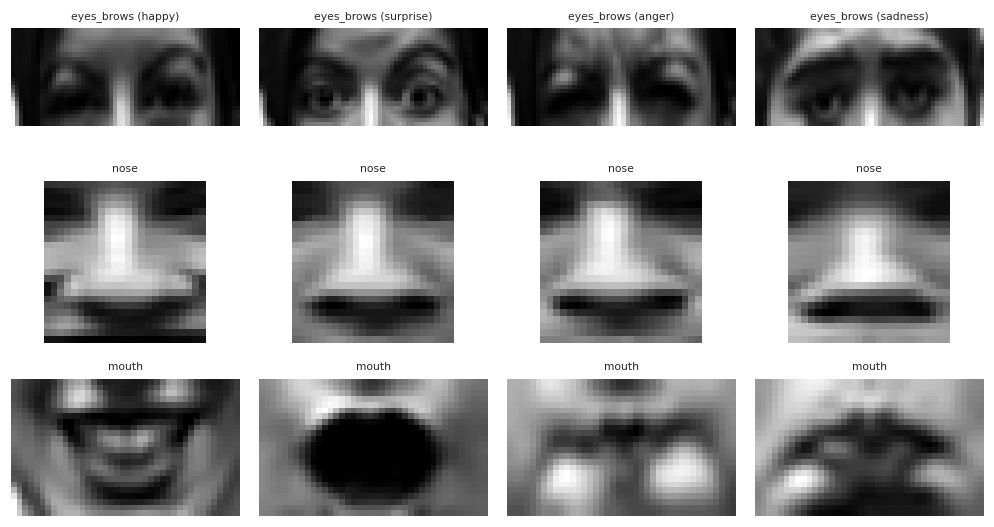

In [28]:
# ----- patchs d'apparence guidés par les landmarks (yeux+sourcils / nez / bouche)
REGIONS = {"eyes_brows": (list(range(17, 27)) + list(range(36, 48)), (24, 56)),
           "nose": (list(range(27, 36)), (24, 24)),
           "mouth": (list(range(48, 68)), (24, 40))}                 # (indices, (hauteur, largeur) du patch normalisé)

def crop_region(img, lm, idx, hw, pad=0.2):
    pts = lm[idx]; x0, y0 = pts.min(0); x1, y1 = pts.max(0)
    w, h = max(x1 - x0, 6), max(y1 - y0, 6); px, py = pad * w, pad * h
    xa, xb = int(max(0, np.floor(x0 - px))), int(min(img.shape[1], np.ceil(x1 + px)))
    ya, yb = int(max(0, np.floor(y0 - py))), int(min(img.shape[0], np.ceil(y1 + py)))
    if xb - xa < 4: xa, xb = max(0, xa - 2), min(img.shape[1], xb + 2)
    if yb - ya < 4: ya, yb = max(0, ya - 2), min(img.shape[0], yb + 2)
    return cv2.resize(img[ya:yb, xa:xb], (hw[1], hw[0]), interpolation=cv2.INTER_CUBIC)

def region_features(img, lm):
    out = []
    for nm, (idx, hw) in REGIONS.items():
        p = crop_region(img, lm, idx, hw)
        out.append(hog(p, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True))
        out.append(lbp_hist(p, 8, 1, "uniform", (2, 2)))
    return np.concatenate(out)

X_region, t_region = timeit(lambda: np.stack([region_features(im, lm) for im, lm in zip(X_img, LM_MEAN)]).astype(np.float32))
print("Patchs guidés par landmarks :", X_region.shape, f"| {t_region:.1f}s")

fig, axes = plt.subplots(3, len(show_classes), figsize=(2.3 * len(show_classes), 5.2))
for k, c in enumerate(show_classes):
    i = np.where(df.emotion.values == c)[0][0]
    for r, (nm, (idx, hw)) in enumerate(REGIONS.items()):
        axes[r, k].imshow(crop_region(X_img[i], LM_MEAN[i], idx, hw), cmap="gray"); axes[r, k].axis("off")
        axes[r, k].set_title(f"{nm} ({c})" if r == 0 else nm, fontsize=7)
plt.tight_layout(); plt.show()

## 8.4 Expériences : géométrie seule, ajout de l'incertitude, fusion avec HOG/LBP

Étapes (même protocole que le TP1 : sujets séparés, plis groupés, macro-F1, pondération des classes) :
1. Comparer **LM-coords / LM-geo / LM-dense** (+ **UNC**) seules ; retenir la meilleure géométrie **sur la validation**.
2. **Fusion précoce** `HOG + LBP + GEO` (+ `UNC`, + `REGION`) avec `BlockScaler`.
3. **Sélection de caractéristiques** sur la meilleure fusion (même procédure qu'en Partie 6).
4. **Fusion tardive** (moyenne de probabilités de SVM par bloc) en comparaison.
5. Contrôle de robustesse : CV groupée répétée sur **tous** les sujets.

In [29]:
run_experiment("LM-coords", X_coords, extract_time=0.0)
run_experiment("LM-geo", X_geo, extract_time=0.0)
run_experiment("LM-dense", X_dense, extract_time=0.0)
X_geo_unc = np.hstack([X_geo, X_unc]); BLK_GU = [(0, X_geo.shape[1]), (X_geo.shape[1], X_geo_unc.shape[1])]
run_experiment("LM-geo+unc", X_geo_unc, blocks=BLK_GU)

lm_tab = results_df(); lm_tab = lm_tab[lm_tab.representation.str.startswith("LM-")]
display(lm_tab[["representation", "classifier", "n_features", "cv_f1_mean", "cv_f1_std", "test_macro_f1", "test_accuracy", "refit_s"]].round(4))

cand = {"LM-coords": X_coords, "LM-geo": X_geo, "LM-dense": X_dense}
GEO_REP = max(cand, key=lambda r: best_row(r, exact=True).cv_f1_mean); X_GEO = cand[GEO_REP]
print(f"\n=> Géométrie retenue pour la fusion (validation) : {GEO_REP} ({X_GEO.shape[1]} dim, CV macro-F1 = {best_row(GEO_REP, exact=True).cv_f1_mean:.3f})")

[LM-coords                              | SVM] CV macro-F1 = 0.759 ± 0.032 | test macro-F1 = 0.811 | acc = 0.839 | 2s
[LM-coords                              | RF ] CV macro-F1 = 0.666 ± 0.037 | test macro-F1 = 0.673 | acc = 0.747 | 53s
[LM-coords                              | XGB] CV macro-F1 = 0.749 ± 0.043 | test macro-F1 = 0.762 | acc = 0.820 | 10s
[LM-geo                                 | SVM] CV macro-F1 = 0.864 ± 0.047 | test macro-F1 = 0.893 | acc = 0.925 | 1s
[LM-geo                                 | RF ] CV macro-F1 = 0.806 ± 0.018 | test macro-F1 = 0.823 | acc = 0.841 | 37s
[LM-geo                                 | XGB] CV macro-F1 = 0.817 ± 0.041 | test macro-F1 = 0.832 | acc = 0.860 | 7s
[LM-dense                               | SVM] CV macro-F1 = 0.799 ± 0.026 | test macro-F1 = 0.857 | acc = 0.892 | 35s
[LM-dense                               | RF ] CV macro-F1 = 0.750 ± 0.051 | test macro-F1 = 0.697 | acc = 0.782 | 321s
[LM-dense                               | XGB] CV 

,representation,classifier,n_features,cv_f1_mean,cv_f1_std,test_macro_f1,test_accuracy,refit_s
18,LM-coords,SVM,136,0.7588,0.0323,0.8110,0.8387,0.0540
19,LM-coords,RF,136,0.6664,0.0370,0.6726,0.7473,6.4849
20,LM-coords,XGB,136,0.7486,0.0432,0.7616,0.8199,0.5717
21,LM-geo,SVM,80,0.8643,0.0466,0.8930,0.9247,0.0236
22,LM-geo,RF,80,0.8064,0.0175,0.8233,0.8414,1.6581
23,LM-geo,XGB,80,0.8166,0.0406,0.8317,0.8602,0.6035
24,LM-dense,SVM,2278,0.7987,0.0262,0.8573,0.8925,0.6633
25,LM-dense,RF,2278,0.7503,0.0507,0.6967,0.7823,9.3325
26,LM-dense,XGB,2278,0.8202,0.0242,0.7737,0.8253,15.4612
27,LM-geo+unc,SVM,87,0.8894,0.0331,0.8774,0.9140,0.0410



=> Géométrie retenue pour la fusion (validation) : LM-geo (80 dim, CV macro-F1 = 0.864)


In [30]:
dg, du, dr = X_GEO.shape[1], X_unc.shape[1], X_region.shape[1]
t_geo = 0.0
# (a) HOG+LBP+GEO
X_f1 = np.hstack([X_hog_b, X_lbp_b, X_GEO]); B1 = [(0, dh), (dh, dh + dl), (dh + dl, dh + dl + dg)]
run_experiment(f"FUSION|HOG+LBP+{GEO_REP}", X_f1, blocks=B1, extract_time=t_fus)
# (b) + incertitude (LUVLi / TTA)
X_f2 = np.hstack([X_f1, X_unc]); B2 = B1 + [(B1[-1][1], B1[-1][1] + du)]
run_experiment(f"FUSION|HOG+LBP+{GEO_REP}+UNC", X_f2, blocks=B2, extract_time=t_fus)
# (c) + patchs guidés par les landmarks  (idée hybride complète)
X_f3 = np.hstack([X_f2, X_region]); B3 = B2 + [(B2[-1][1], B2[-1][1] + dr)]
run_experiment(f"FUSION|HOG+LBP+{GEO_REP}+UNC+REGION", X_f3, blocks=B3, extract_time=t_fus + t_region)
# (d) sans HOG/LBP globaux : tout guidé par les landmarks
X_f4 = np.hstack([X_GEO, X_unc, X_region]); B4 = [(0, dg), (dg, dg + du), (dg + du, dg + du + dr)]
run_experiment(f"FUSION|{GEO_REP}+UNC+REGION", X_f4, blocks=B4, extract_time=t_region)

fus_tab = results_df(); fus_tab = fus_tab[fus_tab.representation.str.startswith("FUSION|")]
display(fus_tab[["representation", "classifier", "n_features", "cv_f1_mean", "cv_f1_std", "test_macro_f1", "test_accuracy", "refit_s", "pred_ms_img"]].round(4))

[FUSION|HOG+LBP+LM-geo                  | SVM] CV macro-F1 = 0.884 ± 0.045 | test macro-F1 = 0.938 | acc = 0.952 | 78s
[FUSION|HOG+LBP+LM-geo                  | RF ] CV macro-F1 = 0.818 ± 0.064 | test macro-F1 = 0.843 | acc = 0.852 | 392s
[FUSION|HOG+LBP+LM-geo                  | XGB] CV macro-F1 = 0.835 ± 0.033 | test macro-F1 = 0.797 | acc = 0.833 | 343s
[FUSION|HOG+LBP+LM-geo+UNC              | SVM] CV macro-F1 = 0.897 ± 0.033 | test macro-F1 = 0.956 | acc = 0.962 | 81s
[FUSION|HOG+LBP+LM-geo+UNC              | RF ] CV macro-F1 = 0.829 ± 0.066 | test macro-F1 = 0.822 | acc = 0.833 | 399s
[FUSION|HOG+LBP+LM-geo+UNC              | XGB] CV macro-F1 = 0.837 ± 0.043 | test macro-F1 = 0.809 | acc = 0.841 | 339s
[FUSION|HOG+LBP+LM-geo+UNC+REGION       | SVM] CV macro-F1 = 0.923 ± 0.030 | test macro-F1 = 0.978 | acc = 0.978 | 114s
[FUSION|HOG+LBP+LM-geo+UNC+REGION       | RF ] CV macro-F1 = 0.818 ± 0.070 | test macro-F1 = 0.819 | acc = 0.831 | 518s
[FUSION|HOG+LBP+LM-geo+UNC+REGION       | 

,representation,classifier,n_features,cv_f1_mean,cv_f1_std,test_macro_f1,test_accuracy,refit_s,pred_ms_img
12,FUSION|HOG+LBP,SVM,3556,0.8382,0.0737,0.8756,0.8871,3.9482,4.5755
13,FUSION|HOG+LBP,RF,3556,0.6054,0.0452,0.6541,0.7312,95.6635,0.1007
14,FUSION|HOG+LBP,XGB,3556,0.6984,0.0234,0.6859,0.7634,14.9229,0.0235
30,FUSION|HOG+LBP+LM-geo,SVM,3636,0.8838,0.0449,0.9382,0.9516,2.1472,3.1143
31,FUSION|HOG+LBP+LM-geo,RF,3636,0.8179,0.0641,0.8425,0.8522,82.0019,0.0940
32,FUSION|HOG+LBP+LM-geo,XGB,3636,0.8353,0.0327,0.7969,0.8333,25.7447,0.0289
33,FUSION|HOG+LBP+LM-geo+UNC,SVM,3643,0.8973,0.0327,0.9565,0.9624,2.1450,3.3166
34,FUSION|HOG+LBP+LM-geo+UNC,RF,3643,0.8289,0.0657,0.8224,0.8333,83.8901,0.0955
35,FUSION|HOG+LBP+LM-geo+UNC,XGB,3643,0.8374,0.0427,0.8092,0.8414,15.6949,0.0237
36,FUSION|HOG+LBP+LM-geo+UNC+REGION,SVM,4627,0.9233,0.0301,0.9781,0.9785,2.7988,4.2477


Meilleure fusion (validation) : FUSION|LM-geo+UNC+REGION | dimension : 1071
k* (règle 1-SE) = 400 sur 1071 caractéristiques | meilleur k brut = 800


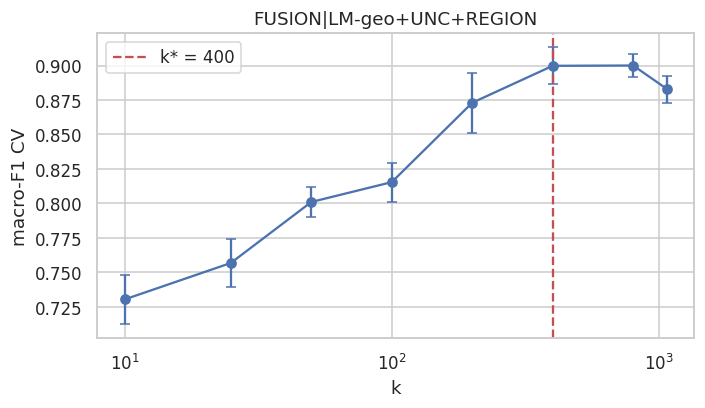

Stabilité (Jaccard moyen) = 0.85 | composition des 400 caractéristiques retenues : {'LM-geo': 72, 'UNC': 3, 'REGION': 325}
[SELECT|LM-geo+UNC+REGION|k400          | SVM] CV macro-F1 = 0.936 ± 0.027 | test macro-F1 = 0.912 | acc = 0.925 | 6s
[SELECT|LM-geo+UNC+REGION|k400          | RF ] CV macro-F1 = 0.857 ± 0.051 | test macro-F1 = 0.852 | acc = 0.871 | 79s
[SELECT|LM-geo+UNC+REGION|k400          | XGB] CV macro-F1 = 0.857 ± 0.016 | test macro-F1 = 0.878 | acc = 0.887 | 27s


,representation,classifier,n_used,cv_f1_mean,cv_f1_std,test_macro_f1,test_accuracy,refit_s,pred_ms_img
42,SELECT|LM-geo+UNC+REGION|k400,SVM,400,0.9359,0.0267,0.9123,0.9247,0.1329,0.2272
43,SELECT|LM-geo+UNC+REGION|k400,RF,400,0.8571,0.0506,0.8522,0.8710,3.8673,0.0519
44,SELECT|LM-geo+UNC+REGION|k400,XGB,400,0.8566,0.0160,0.8783,0.8871,1.2670,0.0152


In [31]:
# ----- sélection de caractéristiques sur la meilleure fusion (validation) — même procédure qu'en Partie 6
XB = {f"FUSION|HOG+LBP+{GEO_REP}": (X_f1, B1), f"FUSION|HOG+LBP+{GEO_REP}+UNC": (X_f2, B2),
      f"FUSION|HOG+LBP+{GEO_REP}+UNC+REGION": (X_f3, B3), f"FUSION|{GEO_REP}+UNC+REGION": (X_f4, B4)}
FUS_BEST = max(XB, key=lambda r: best_row(r, exact=True).cv_f1_mean)
X_best, B_best = XB[FUS_BEST]
print("Meilleure fusion (validation) :", FUS_BEST, "| dimension :", X_best.shape[1])
K_BEST, curve_best = choose_k(X_best, B_best)
plt.figure(figsize=(7, 3.6)); plt.errorbar(curve_best.k, curve_best["mean"], yerr=curve_best.se, marker="o", capsize=3)
plt.axvline(K_BEST, color="r", ls="--", label=f"k* = {K_BEST}"); plt.xscale("log"); plt.legend(); plt.xlabel("k"); plt.ylabel("macro-F1 CV"); plt.title(FUS_BEST); plt.show()

names_blk = {"HOG": 0, "LBP": 1}
blk_names = (["HOG", "LBP"] if "HOG+LBP" in FUS_BEST else []) + [GEO_REP] + (["UNC"] if "UNC" in FUS_BEST else []) + (["REGION"] if "REGION" in FUS_BEST else [])
jac, comp = selection_stability(X_best, B_best, K_BEST, blk_names)
print(f"Stabilité (Jaccard moyen) = {jac:.2f} | composition des {K_BEST} caractéristiques retenues :", comp)
SEL_REP = f"SELECT|{FUS_BEST.split('|')[1]}|k{K_BEST}"
run_experiment(SEL_REP, X_best, blocks=B_best, sel_k=K_BEST, extract_time=np.nan)
_d = results_df(); display(_d[_d.representation == SEL_REP][["representation", "classifier", "n_used", "cv_f1_mean", "cv_f1_std", "test_macro_f1", "test_accuracy", "refit_s", "pred_ms_img"]].round(4))

In [32]:
# ----- fusion TARDIVE : moyenne des probabilités de SVM entraînés séparément sur chaque bloc
def svm_params(rep):
    d = results_df(); r = d[(d.representation == rep) & (d.classifier == "SVM")].iloc[0]
    return {k: v for k, v in r.best_params.items()}

LATE_BLOCKS = {f"HOG|{HOG_BEST_CFG}": X_hog_b, f"LBP|{LBP_BEST_CFG}": X_lbp_b, GEO_REP: X_GEO}
def late_pipe(rep):
    return Pipeline([("prep", BlockScaler()), ("clf", SVC(class_weight="balanced", probability=True, random_state=SEED, **svm_params(rep)))])

def late_fit_predict(tr, te):
    P = 0
    for rep, X_ in LATE_BLOCKS.items():
        m = late_pipe(rep).fit(X_[tr], y[tr]); p = m.predict_proba(X_[te])
        full = np.zeros((len(te), len(CLASSES))); full[:, m.classes_] = p; P = P + full
    return P / len(LATE_BLOCKS)

cv_scores = []
for a, b in cv_splits:
    P = late_fit_predict(tr_idx[a], tr_idx[b]); cv_scores.append(f1_score(y[tr_idx[b]], P.argmax(1), average="macro"))
P_te = late_fit_predict(tr_idx, te_idx); pred_late = P_te.argmax(1)
row = dict(representation="LATE|HOG+LBP+" + GEO_REP, classifier="SVM-avg", n_features=sum(v.shape[1] for v in LATE_BLOCKS.values()),
           n_used=sum(v.shape[1] for v in LATE_BLOCKS.values()), best_params={"blocks": list(LATE_BLOCKS)}, cv_f1_mean=float(np.mean(cv_scores)),
           cv_f1_std=float(np.std(cv_scores)), cv_folds=cv_scores, extract_s=t_fus, search_s=np.nan, refit_s=np.nan, pred_ms_img=np.nan,
           **{f"test_{k}": v for k, v in metrics_dict(y_te, pred_late).items()})
RESULTS.append(row); MODELS[(row["representation"], "SVM-avg")] = dict(est=None, pred=pred_late, sel_k=None, blocks=None)
print(f"Fusion tardive : CV macro-F1 = {row['cv_f1_mean']:.3f} ± {row['cv_f1_std']:.3f} | test macro-F1 = {row['test_macro_f1']:.3f}")

Fusion tardive : CV macro-F1 = 0.873 ± 0.028 | test macro-F1 = 0.878


In [33]:
# ----- contrôle de robustesse : CV groupée répétée sur TOUS les sujets (SVM aux hyperparamètres déjà choisis)
REP_TABLE = {f"HOG|{HOG_BEST_CFG}": (HOG_X[HOG_BEST_CFG], None), f"LBP|{LBP_BEST_CFG}": (LBP_X[LBP_BEST_CFG], None),
             "FUSION|HOG+LBP": (X_fus, BLK_FUS), GEO_REP: (X_GEO, None), **{k: v for k, v in XB.items()}}
def robust_cv(rep, Xall, blocks, n_rep=3):
    p = svm_params(rep); sc = []
    for s in range(n_rep):
        for a, b in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 100 + s).split(Xall, y, groups):
            pipe = build_pipe("SVM", blocks).set_params(**{"clf__" + k: v for k, v in p.items()})
            sc.append(f1_score(y[b], pipe.fit(Xall[a], y[a]).predict(Xall[b]), average="macro"))
    return np.array(sc)

def has_svm(rep):
    d = results_df(); return bool(((d.representation == rep) & (d.classifier == "SVM")).any())
ROBUST = {rep: robust_cv(rep, X_, B_, n_rep=1 if QUICK else 3) for rep, (X_, B_) in REP_TABLE.items() if has_svm(rep)}
base = f"FUSION|HOG+LBP"
rob = pd.DataFrame([dict(representation=r, macroF1_moy=s.mean(), macroF1_std=s.std(), delta_vs_HOG_LBP=(s - ROBUST[base]).mean() if base in ROBUST else np.nan) for r, s in ROBUST.items()])
display(rob.sort_values("macroF1_moy", ascending=False).round(4))
try:
    from scipy.stats import wilcoxon
    for r, s in ROBUST.items():
        if r != base and base in ROBUST and r.startswith("FUSION|HOG+LBP+"):
            print(f"Wilcoxon appairé {r} vs {base} : p = {wilcoxon(s, ROBUST[base]).pvalue:.3f}  (plis non indépendants : à lire comme indicatif)")
except Exception as e:
    print("Wilcoxon non calculé :", e)

,representation,macroF1_moy,macroF1_std,delta_vs_HOG_LBP
6,FUSION|HOG+LBP+LM-geo+UNC+REGION,0.9376,0.0340,0.0779
5,FUSION|HOG+LBP+LM-geo+UNC,0.9280,0.0335,0.0683
7,FUSION|LM-geo+UNC+REGION,0.9256,0.0412,0.0659
4,FUSION|HOG+LBP+LM-geo,0.9250,0.0376,0.0652
3,LM-geo,0.8872,0.0669,0.0275
2,FUSION|HOG+LBP,0.8597,0.0448,0.0000
0,HOG|ppc6_o9_b3,0.8463,0.0367,-0.0134
1,LBP|P8R1_g8,0.6694,0.0501,-0.1903


Wilcoxon appairé FUSION|HOG+LBP+LM-geo vs FUSION|HOG+LBP : p = 0.000  (plis non indépendants : à lire comme indicatif)
Wilcoxon appairé FUSION|HOG+LBP+LM-geo+UNC vs FUSION|HOG+LBP : p = 0.000  (plis non indépendants : à lire comme indicatif)
Wilcoxon appairé FUSION|HOG+LBP+LM-geo+UNC+REGION vs FUSION|HOG+LBP : p = 0.000  (plis non indépendants : à lire comme indicatif)


# Partie 9 — Analyse comparative finale

Règle d'or appliquée partout : **les choix (configuration, classifieur, k, représentation) sont faits sur la validation croisée groupée**, le test n'est que rapporté. Un score de test n'est jamais utilisé pour sélectionner un modèle.

,rank_cv,representation,classifier,n_features,n_used,best_params,cv_f1_mean,cv_f1_std,test_macro_f1,test_balanced_acc,test_accuracy,test_weighted_f1,extract_s,refit_s,pred_ms_img
42,1,SELECT|LM-geo+UNC+REGION|k400,SVM,1071,400,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.9359,0.0267,0.9123,0.9131,0.9247,0.9233,NaN,0.1329,0.2272
39,2,FUSION|LM-geo+UNC+REGION,SVM,1071,1071,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.9270,0.0341,0.9469,0.9435,0.9489,0.9490,4.2083,0.3737,0.6747
36,3,FUSION|HOG+LBP+LM-geo+UNC+REGION,SVM,4627,4627,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.9233,0.0301,0.9781,0.9762,0.9785,0.9782,8.1491,2.7988,4.2477
33,4,FUSION|HOG+LBP+LM-geo+UNC,SVM,3643,3643,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.8973,0.0327,0.9565,0.9597,0.9624,0.9614,3.9408,2.1450,3.3166
27,5,LM-geo+unc,SVM,87,87,"{'C': 1, 'kernel': 'linear'}",0.8894,0.0331,0.8774,0.8798,0.9140,0.9111,NaN,0.0410,0.0197
30,6,FUSION|HOG+LBP+LM-geo,SVM,3636,3636,"{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}",0.8838,0.0449,0.9382,0.9464,0.9516,0.9484,3.9408,2.1472,3.1143
45,7,LATE|HOG+LBP+LM-geo,SVM-avg,3636,3636,"{'blocks': ['HOG|ppc6_o9_b3', 'LBP|P8R1_g8', 'LM-geo']}",0.8733,0.0281,0.8783,0.8702,0.9086,0.9044,3.9408,NaN,NaN
21,8,LM-geo,SVM,80,80,"{'C': 1, 'kernel': 'linear'}",0.8643,0.0466,0.8930,0.8952,0.9247,0.9222,0.0000,0.0236,0.0221
43,9,SELECT|LM-geo+UNC+REGION|k400,RF,1071,400,"{'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 'sqrt...",0.8571,0.0506,0.8522,0.8294,0.8710,0.8708,NaN,3.8673,0.0519
44,10,SELECT|LM-geo+UNC+REGION|k400,XGB,1071,400,"{'subsample': 0.7, 'n_estimators': 100, 'max_depth': 3, 'learning_...",0.8566,0.0160,0.8783,0.8722,0.8871,0.8850,NaN,1.2670,0.0152


Tableau enregistré : resultats_finaux.csv  (traitement du déséquilibre : pondération des classes dans TOUS les modèles ; ablation plus bas)


,classifieur,dim,cv_macroF1,test_macroF1,test_acc
HOG,SVM,2916,0.831734,0.845686,0.88172
LBP,SVM,640,0.672339,0.661348,0.725806
HOG+LBP,SVM,3556,0.838203,0.875583,0.887097
LM-geo,SVM,80,0.864296,0.893016,0.924731
LM-geo+unc,SVM,87,0.889386,0.877408,0.913978
LM-geo+UNC+REGION (fusion),SVM,1071,0.926984,0.946933,0.948925
sélection,SVM,400,0.935925,0.912252,0.924731


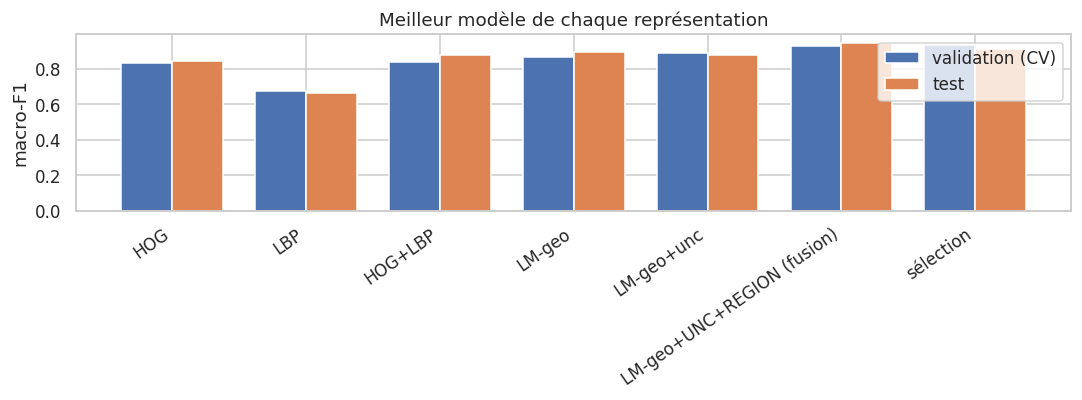

In [34]:
from IPython.display import Markdown
ALL = results_df().copy()
ALL["rank_cv"] = ALL.cv_f1_mean.rank(ascending=False, method="min").astype(int)
cols = ["representation", "classifier", "n_features", "n_used", "best_params", "cv_f1_mean", "cv_f1_std", "test_macro_f1",
        "test_balanced_acc", "test_accuracy", "test_weighted_f1", "extract_s", "refit_s", "pred_ms_img"]
FINAL = ALL.sort_values("cv_f1_mean", ascending=False)[["rank_cv"] + cols]
pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 250)
display(FINAL.round(4))
FINAL.to_csv("resultats_finaux.csv", index=False)
print("Tableau enregistré : resultats_finaux.csv  (traitement du déséquilibre : pondération des classes dans TOUS les modèles ; ablation plus bas)")

# meilleure ligne par famille de représentation
fam = {"HOG": best_row("HOG"), "LBP": best_row("LBP"), "HOG+LBP": best_row("FUSION|HOG+LBP", exact=True),
       GEO_REP: best_row(GEO_REP, exact=True), "LM-geo+unc": best_row("LM-geo+unc", exact=True),
       FUS_BEST.replace("FUSION|", "") + " (fusion)": best_row(FUS_BEST, exact=True), "sélection": best_row(SEL_REP, exact=True)}
fam_df = pd.DataFrame({k: dict(classifieur=v.classifier, dim=v.n_used, cv_macroF1=v.cv_f1_mean, test_macroF1=v.test_macro_f1, test_acc=v.test_accuracy) for k, v in fam.items()}).T
display(fam_df.round(4))
fig, ax = plt.subplots(figsize=(10, 3.8)); x_ = np.arange(len(fam_df)); w = .38
ax.bar(x_ - w / 2, fam_df.cv_macroF1.astype(float), w, label="validation (CV)"); ax.bar(x_ + w / 2, fam_df.test_macroF1.astype(float), w, label="test")
ax.set_xticks(x_); ax.set_xticklabels(fam_df.index, rotation=35, ha="right"); ax.set_ylabel("macro-F1"); ax.legend(); ax.set_title("Meilleur modèle de chaque représentation")
plt.tight_layout(); plt.show()

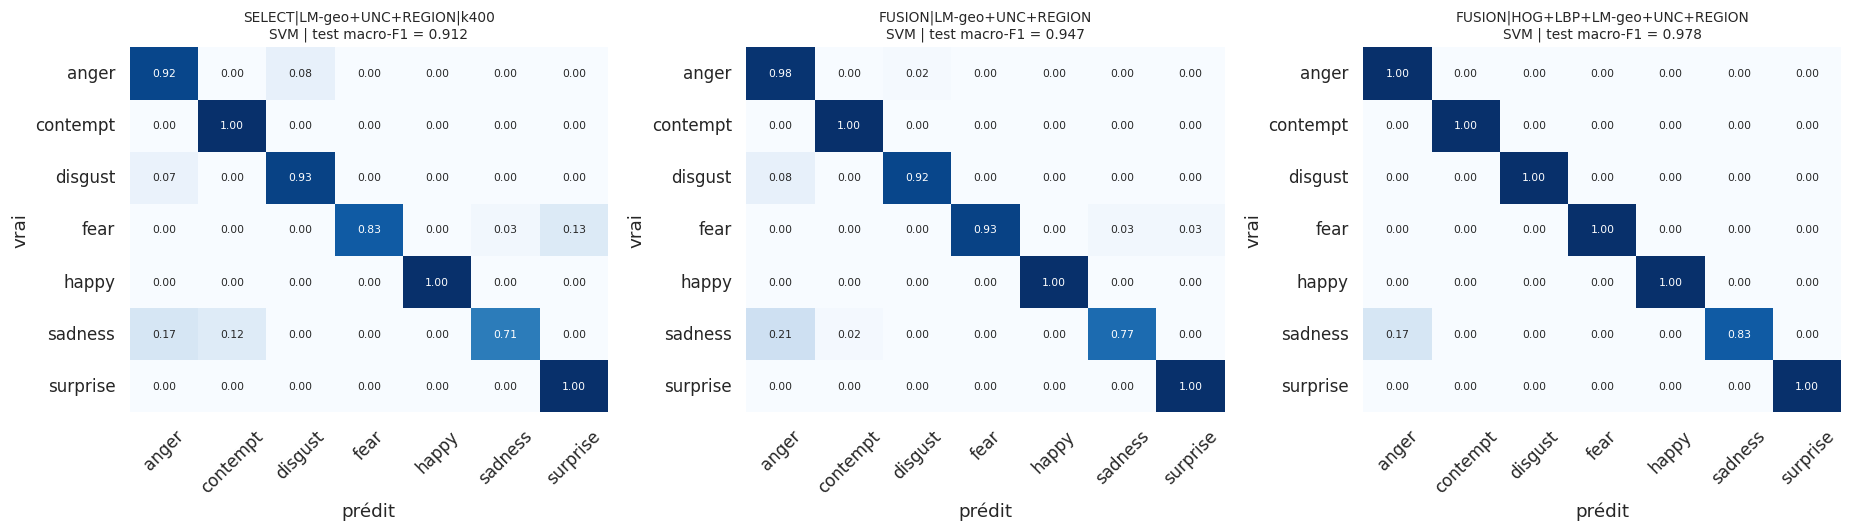

,HOG,LBP,HOG+LBP,LM-geo,LM-geo+unc,LM-geo+UNC+REGION (fusion),sélection,n_train,n_test
anger,0.754,0.542,0.667,0.896,0.902,0.881,0.866,210,60
contempt,0.500,0.545,0.818,0.667,0.632,0.980,0.889,84,24
disgust,0.923,0.786,0.915,1.000,1.000,0.948,0.926,294,60
fear,0.968,0.364,0.933,0.966,0.929,0.966,0.909,120,30
happy,0.969,0.845,1.000,0.992,1.000,1.000,1.000,348,66
sadness,0.818,0.583,0.808,0.737,0.703,0.860,0.819,120,48
surprise,0.988,0.964,0.988,0.994,0.977,0.994,0.977,414,84


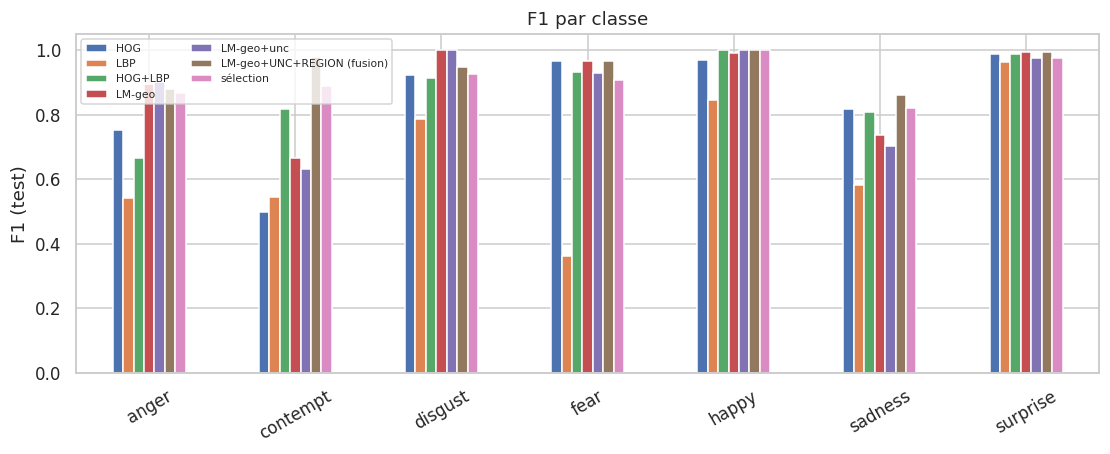

In [35]:
# ----- matrices de confusion normalisées des 3 meilleurs modèles (classés sur la VALIDATION)
top3 = ALL[ALL.classifier != "SVM-avg"].sort_values("cv_f1_mean", ascending=False).head(3)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (_, r) in zip(axes, top3.iterrows()):
    plot_cm(ax, y_te, MODELS[(r.representation, r.classifier)]["pred"], f"{r.representation}\n{r.classifier} | test macro-F1 = {r.test_macro_f1:.3f}")
plt.tight_layout(); plt.show()

# ----- F1 par classe (test) des meilleures représentations
pc = {k: f1_score(y_te, MODELS[(v.representation, v.classifier)]["pred"], average=None, labels=range(len(CLASSES)), zero_division=0) for k, v in fam.items()}
pc_df = pd.DataFrame(pc, index=CLASSES); pc_df["n_train"] = np.bincount(y_tr, minlength=len(CLASSES)); pc_df["n_test"] = np.bincount(y_te, minlength=len(CLASSES))
display(pc_df.round(3))
pc_df.drop(columns=["n_train", "n_test"]).plot.bar(figsize=(12, 4)); plt.ylabel("F1 (test)"); plt.title("F1 par classe"); plt.xticks(rotation=30); plt.legend(fontsize=7, ncol=2); plt.show()

Modèle : SELECT|LM-geo+UNC+REGION|k400 + SVM | 28 erreurs sur 372 images de test


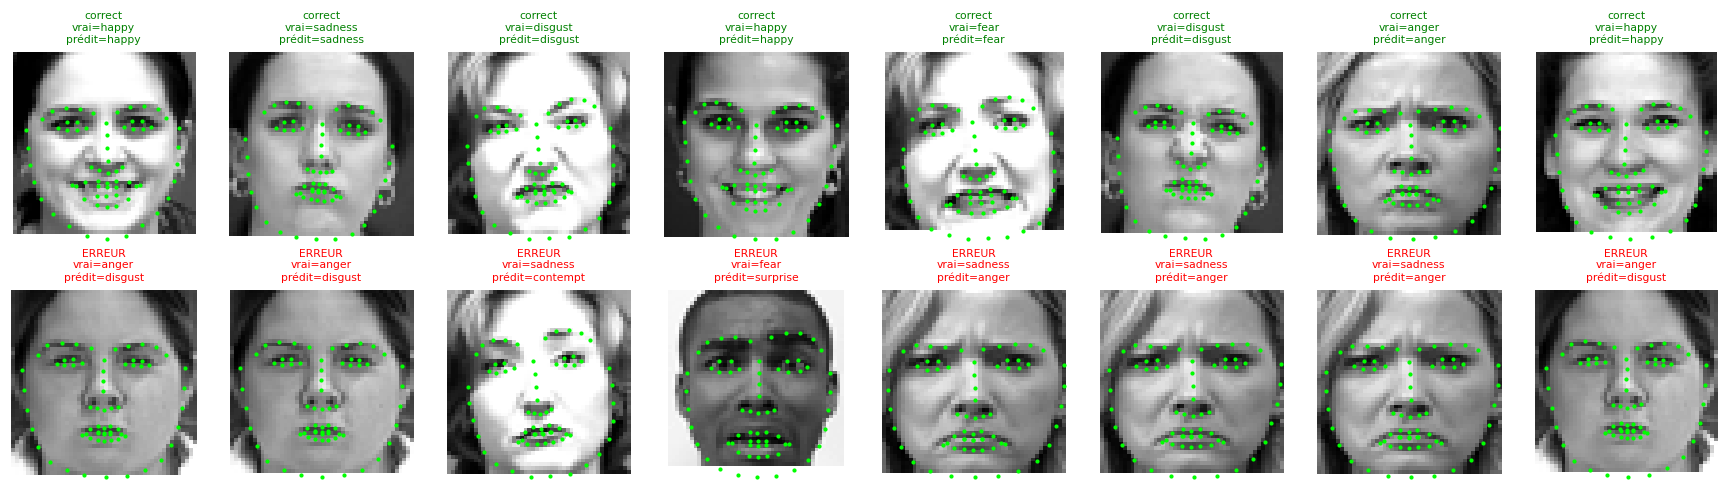

Incertitude moyenne des landmarks : images erronées = 0.291 px vs correctes = 0.269 px


In [36]:
# ----- exemples correctement / incorrectement classés (meilleur modèle selon la validation)
bestA = top3.iloc[0]; predA = MODELS[(bestA.representation, bestA.classifier)]["pred"]
ok_i, bad_i = np.where(predA == y_te)[0], np.where(predA != y_te)[0]
print(f"Modèle : {bestA.representation} + {bestA.classifier} | {len(bad_i)} erreurs sur {len(y_te)} images de test")
n_show = 8
fig, axes = plt.subplots(2, n_show, figsize=(2 * n_show, 4.6))
for row_, idxs, ttl in [(0, rng.choice(ok_i, min(n_show, len(ok_i)), replace=False) if len(ok_i) else [], "correct"),
                        (1, rng.choice(bad_i, min(n_show, len(bad_i)), replace=False) if len(bad_i) else [], "ERREUR")]:
    for k in range(n_show):
        ax = axes[row_, k]; ax.axis("off")
        if k < len(idxs):
            gi = te_idx[idxs[k]]; ax.imshow(X_img[gi], cmap="gray")
            ax.scatter(LM_MEAN[gi, :, 0], LM_MEAN[gi, :, 1], s=3, c="lime")
            ax.set_title(f"{ttl}\nvrai={CLASSES[y_te[idxs[k]]]}\nprédit={CLASSES[predA[idxs[k]]]}", fontsize=7, color="green" if ttl == "correct" else "red")
plt.tight_layout(); plt.show()
if len(bad_i):
    te_unc = LM_STD[te_idx].mean(1)
    print("Incertitude moyenne des landmarks : images erronées = %.3f px vs correctes = %.3f px" % (te_unc[bad_i].mean(), te_unc[ok_i].mean()))

In [37]:
# ----- ablation du traitement du déséquilibre (pondération des classes) sur le meilleur modèle
rep, clf = bestA.representation, bestA.classifier
est = clone(MODELS[(rep, clf)]["est"])
if clf in ("SVM", "RF"): est.set_params(clf__class_weight=None)
est.fit(REP_X[rep][tr_idx], y_tr)                                   # XGBoost : sans sample_weight
p_nw = est.predict(REP_X[rep][te_idx]); p_w = MODELS[(rep, clf)]["pred"]
abl = pd.DataFrame({"n_train": np.bincount(y_tr, minlength=len(CLASSES)),
                    "F1 sans poids": f1_score(y_te, p_nw, average=None, labels=range(len(CLASSES)), zero_division=0),
                    "F1 avec poids": f1_score(y_te, p_w, average=None, labels=range(len(CLASSES)), zero_division=0)}, index=CLASSES)
abl["Δ"] = abl["F1 avec poids"] - abl["F1 sans poids"]
display(abl.sort_values("n_train").round(3))
m_nw, m_w = metrics_dict(y_te, p_nw), metrics_dict(y_te, p_w)
print(f"macro-F1 : sans poids = {m_nw['macro_f1']:.3f} | avec poids = {m_w['macro_f1']:.3f} || accuracy : {m_nw['accuracy']:.3f} vs {m_w['accuracy']:.3f}")
minor = abl.sort_values("n_train").index[:3].tolist()
dm = abl.loc[minor, "Δ"].mean()

,n_train,F1 sans poids,F1 avec poids,Δ
contempt,84,0.868,0.889,0.021
fear,120,0.909,0.909,0.000
sadness,120,0.805,0.819,0.014
anger,210,0.859,0.866,0.007
disgust,294,0.934,0.926,-0.009
happy,348,1.000,1.000,0.000
surprise,414,0.977,0.977,0.000


macro-F1 : sans poids = 0.907 | avec poids = 0.912 || accuracy : 0.922 vs 0.925


In [38]:
# ----- réponses chiffrées (générées à partir des résultats)
def rep_label(r): return f"{r.representation} + {r.classifier}"
L = []
bcv = ALL[ALL.classifier != "SVM-avg"].sort_values("cv_f1_mean", ascending=False).iloc[0]
bte = ALL.sort_values("test_macro_f1", ascending=False).iloc[0]
L.append(f"**Q1 — Meilleure macro-F1.** Sur la **validation** (critère de sélection) : `{rep_label(bcv)}` avec {bcv.cv_f1_mean:.3f} ± {bcv.cv_f1_std:.3f} (test : {bcv.test_macro_f1:.3f}). "
         f"Sur le **test seul** le plus haut score est {bte.test_macro_f1:.3f} (`{rep_label(bte)}`) ; on ne s'en sert pas pour choisir, car avec ~{len(te_idx)} images de test l'écart est dans le bruit.")

se = bcv.cv_f1_std / np.sqrt(N_FOLDS)
near = ALL[(ALL.classifier != "SVM-avg") & (ALL.cv_f1_mean >= bcv.cv_f1_mean - se)].sort_values(["n_used", "pred_ms_img"])
cmpr = near.iloc[0]
L.append(f"**Q2 — Meilleur compromis.** Parmi les modèles à ≤ 1 erreur standard du meilleur, le plus léger est `{rep_label(cmpr)}` : {int(cmpr.n_used)} caractéristiques, "
         f"CV {cmpr.cv_f1_mean:.3f}, test {cmpr.test_macro_f1:.3f}, prédiction {cmpr.pred_ms_img:.3f} ms/image.")

f1c = pc_df.drop(columns=["n_train", "n_test"]).mean(1).sort_values()
L.append(f"**Q3 — Classes faciles / difficiles** (F1 test moyen sur les représentations ci-dessus) : plus faciles = {', '.join(f1c.index[::-1][:2])} ; plus difficiles = {', '.join(f1c.index[:2])}.")

from collections import Counter
cnt_conf = Counter()
for _, r in ALL[ALL.classifier != "SVM-avg"].sort_values("cv_f1_mean", ascending=False).head(6).iterrows():
    for a_, b_, v in top_confusions(y_te, MODELS[(r.representation, r.classifier)]["pred"], k=3): cnt_conf[(a_, b_)] += 1
L.append("**Q4 — Confusions récurrentes** (dans le top-3 des confusions des 6 meilleurs modèles) : " + ", ".join(f"{a_}→{b_} ({n}/6)" for (a_, b_), n in cnt_conf.most_common(4)) + ".")

L.append(f"**Q5 — Déséquilibre.** Classes minoritaires ({', '.join(minor)}) : Δ F1 moyen avec/sans pondération = {dm:+.3f} ; macro-F1 {m_nw['macro_f1']:.3f} → {m_w['macro_f1']:.3f}. "
         + ("La pondération aide les classes rares." if dm > 0.01 else ("Effet négligeable sur ce test." if abs(dm) <= 0.01 else "La pondération ne les aide pas ici (à confirmer : test petit).")))

def delta(a, b):
    if a in ROBUST and b in ROBUST:
        d_ = ROBUST[a] - ROBUST[b]; return d_.mean(), d_.std()
    return None
hl, g_ = "FUSION|HOG+LBP", FUS_BEST
bs = max([(f"HOG|{HOG_BEST_CFG}"), (f"LBP|{LBP_BEST_CFG}")], key=lambda k: ROBUST.get(k, np.array([0])).mean())
d1, d2 = delta(hl, bs), delta(g_, hl)
txt = "**Q6 — La fusion est-elle utile ?** (CV groupée répétée sur tous les sujets, SVM) "
if d1: txt += f"HOG+LBP vs meilleur descripteur seul : Δ macro-F1 = {d1[0]:+.3f} (écart-type des écarts {d1[1]:.3f}). "
if d2: txt += f"Fusion avec landmarks (`{g_}`) vs HOG+LBP : Δ = {d2[0]:+.3f} (σ {d2[1]:.3f}). "
if d2: txt += "→ " + ("gain **supérieur à la variabilité** : fusion utile." if d2[0] > d2[1] else ("gain **inférieur à la variabilité entre plis** : non démontré, plutôt équivalent." if d2[0] > 0 else "pas de gain mesurable."))
L.append(txt)
L.append(f"**Q7 — Modèle recommandé.** `{rep_label(cmpr)}` (compromis performance/dimension/temps de la Q2) ; si seule la performance compte : `{rep_label(bcv)}`. "
         "Pour un usage réel il faudrait en outre un détecteur de visage robuste, et le modèle devrait être revalidé sur des données spontanées (Q8).")
L.append("**Q8 — Limites vers des expressions spontanées.** (i) CK+ = expressions **posées, exagérées, au pic**, vue frontale, éclairage de laboratoire, peu de sujets (le test porte sur quelques sujets seulement) ; "
         "(ii) peu de sujets → variance élevée des scores ; (iii) la version 48×48 réduit la résolution des landmarks (précision de quelques pixels) ; (iv) pas de frame neutre : géométrie absolue et dépendante de la morphologie ; "
         "(v) expressions spontanées = plus subtiles, asymétriques, mixtes, avec rotation de tête et occultations — notamment les cas où l'incertitude de LUVLi/TTA devient élevée.")
display(Markdown("\n\n".join(L)))
ANSWERS_MD = "\n\n".join(L)

**Q1 — Meilleure macro-F1.** Sur la **validation** (critère de sélection) : `SELECT|LM-geo+UNC+REGION|k400 + SVM` avec 0.936 ± 0.027 (test : 0.912). Sur le **test seul** le plus haut score est 0.978 (`FUSION|HOG+LBP+LM-geo+UNC+REGION + SVM`) ; on ne s'en sert pas pour choisir, car avec ~372 images de test l'écart est dans le bruit.

**Q2 — Meilleur compromis.** Parmi les modèles à ≤ 1 erreur standard du meilleur, le plus léger est `SELECT|LM-geo+UNC+REGION|k400 + SVM` : 400 caractéristiques, CV 0.936, test 0.912, prédiction 0.227 ms/image.

**Q3 — Classes faciles / difficiles** (F1 test moyen sur les représentations ci-dessus) : plus faciles = surprise, happy ; plus difficiles = contempt, sadness.

**Q4 — Confusions récurrentes** (dans le top-3 des confusions des 6 meilleurs modèles) : sadness→anger (6/6), sadness→contempt (4/6), anger→contempt (2/6), fear→surprise (1/6).

**Q5 — Déséquilibre.** Classes minoritaires (contempt, fear, sadness) : Δ F1 moyen avec/sans pondération = +0.012 ; macro-F1 0.907 → 0.912. La pondération aide les classes rares.

**Q6 — La fusion est-elle utile ?** (CV groupée répétée sur tous les sujets, SVM) HOG+LBP vs meilleur descripteur seul : Δ macro-F1 = +0.013 (écart-type des écarts 0.025). Fusion avec landmarks (`FUSION|LM-geo+UNC+REGION`) vs HOG+LBP : Δ = +0.066 (σ 0.044). → gain **supérieur à la variabilité** : fusion utile.

**Q7 — Modèle recommandé.** `SELECT|LM-geo+UNC+REGION|k400 + SVM` (compromis performance/dimension/temps de la Q2) ; si seule la performance compte : `SELECT|LM-geo+UNC+REGION|k400 + SVM`. Pour un usage réel il faudrait en outre un détecteur de visage robuste, et le modèle devrait être revalidé sur des données spontanées (Q8).

**Q8 — Limites vers des expressions spontanées.** (i) CK+ = expressions **posées, exagérées, au pic**, vue frontale, éclairage de laboratoire, peu de sujets (le test porte sur quelques sujets seulement) ; (ii) peu de sujets → variance élevée des scores ; (iii) la version 48×48 réduit la résolution des landmarks (précision de quelques pixels) ; (iv) pas de frame neutre : géométrie absolue et dépendante de la morphologie ; (v) expressions spontanées = plus subtiles, asymétriques, mixtes, avec rotation de tête et occultations — notamment les cas où l'incertitude de LUVLi/TTA devient élevée.

In [39]:
# ----- conclusion générée
hb_, lb_ = best_row("HOG"), best_row("LBP")
cmd = lambda r: f"`{r.representation.split('|')[-1]}` + {r.classifier} (CV {r.cv_f1_mean:.3f}, test {r.test_macro_f1:.3f})"
fh = best_row("FUSION|HOG+LBP", exact=True); sr = best_row(SEL_REP, exact=True); gr = best_row(GEO_REP, exact=True)
CONCL = f"""## Conclusion
- **CK+** : {len(df)} images, {df.subject.nunique()} sujets, {len(CLASSES)} classes ; déséquilibre max/min = {imb_ratio:.1f} ; évaluation **séparée par sujets** (aucun sujet commun apprentissage/test, vérifié).
- **Meilleur HOG** : {cmd(hb_)}. **Meilleur LBP** : {cmd(lb_)}.
- **Fusion HOG+LBP** : {cmd(fh)} — {"gain" if fh.cv_f1_mean > max(hb_.cv_f1_mean, lb_.cv_f1_mean) else "pas de gain"} en validation par rapport au meilleur descripteur seul.
- **Landmarks ({LM_BACKEND}, {LM_TTA} vues TTA)** : meilleure géométrie `{GEO_REP}` ({X_GEO.shape[1]} dim) → {cmd(gr)}. Meilleure fusion avec landmarks : {cmd(best_row(FUS_BEST, exact=True))}.
- **Sélection de caractéristiques** (ANOVA, k={K_BEST} sur {X_best.shape[1]}) : {cmd(sr)}.
- **Modèle retenu** : voir Q2/Q7 ci-dessus.
- **Limites** : expressions posées, peu de sujets (test petit → intervalles larges), images 48×48, pas de frame neutre, incertitude LUVLi remplacée par une estimation TTA si LUVLi n'est pas branché.
- **Piste d'amélioration réaliste** : (1) landmarks LUVLi natifs sur des images en haute résolution + incertitude/visibilité natives ; (2) déplacements neutre→pic quand la frame neutre existe ; (3) graphe des landmarks + GNN (GLaRE) ou apprentissage profond avec augmentation, évalués en validation croisée *leave-subject-out* complète."""
display(Markdown(CONCL))

## Conclusion
- **CK+** : 1962 images, 118 sujets, 7 classes ; déséquilibre max/min = 4.6 ; évaluation **séparée par sujets** (aucun sujet commun apprentissage/test, vérifié).
- **Meilleur HOG** : `ppc6_o9_b3` + SVM (CV 0.832, test 0.846). **Meilleur LBP** : `P8R1_g8` + SVM (CV 0.672, test 0.661).
- **Fusion HOG+LBP** : `HOG+LBP` + SVM (CV 0.838, test 0.876) — gain en validation par rapport au meilleur descripteur seul.
- **Landmarks (dlib, 8 vues TTA)** : meilleure géométrie `LM-geo` (80 dim) → `LM-geo` + SVM (CV 0.864, test 0.893). Meilleure fusion avec landmarks : `LM-geo+UNC+REGION` + SVM (CV 0.927, test 0.947).
- **Sélection de caractéristiques** (ANOVA, k=400 sur 1071) : `k400` + SVM (CV 0.936, test 0.912).
- **Modèle retenu** : voir Q2/Q7 ci-dessus.
- **Limites** : expressions posées, peu de sujets (test petit → intervalles larges), images 48×48, pas de frame neutre, incertitude LUVLi remplacée par une estimation TTA si LUVLi n'est pas branché.
- **Piste d'amélioration réaliste** : (1) landmarks LUVLi natifs sur des images en haute résolution + incertitude/visibilité natives ; (2) déplacements neutre→pic quand la frame neutre existe ; (3) graphe des landmarks + GNN (GLaRE) ou apprentissage profond avec augmentation, évalués en validation croisée *leave-subject-out* complète.

# Partie 10 — Mini-rapport (généré)

La cellule suivante assemble le **mini-rapport** demandé (`rapport_landmarks.md`) : méthode de détection, état de l'art, caractéristiques retenues et justification, méthode de fusion, expériences/résultats (tableaux issus de **votre** exécution) et analyse. À convertir en PDF/Word si nécessaire (par ex. `pandoc rapport_landmarks.md -o rapport.pdf`).

In [40]:
def md_table(d, floatfmt=".3f"):
    try: return d.to_markdown(index=False, floatfmt=floatfmt)
    except Exception: return d.to_string(index=False)

tab_main = FINAL[["rank_cv", "representation", "classifier", "n_used", "cv_f1_mean", "cv_f1_std", "test_macro_f1", "test_balanced_acc", "test_accuracy", "refit_s", "pred_ms_img"]].head(15).copy()
tab_main.columns = ["rang CV", "représentation", "classifieur", "dim.", "macro-F1 CV", "± CV", "macro-F1 test", "bal. acc. test", "acc. test", "entraînement (s)", "prédiction (ms/img)"]
tab_fam = fam_df.reset_index().rename(columns={"index": "représentation"})
rob_t = rob.sort_values("macroF1_moy", ascending=False)

REPORT = f"""# Mini-rapport — Facial Landmarks pour la reconnaissance des émotions (CK+)

*Généré automatiquement le {pd.Timestamp.now():%d/%m/%Y %H:%M} à partir de l'exécution du notebook.*

## 1. Détection des 68 landmarks
- Détecteur utilisé : **{LM_BACKEND}** (ordre de préférence : LUVLi → dlib [Kazemi & Sullivan 2014] → FAN). Images CK+48 (48×48) agrandies ×4 (192×192, interpolation cubique) ; boîte englobante = image entière (visages déjà recadrés).
- Landmarks finaux = **moyenne de {LM_TTA} vues** (rotation ±6°, échelle ±5 %, translation ±4 %) ; **incertitude** par landmark = dispersion radiale sur ces vues (équivalent opérationnel de l'incertitude de LUVLi, Kumar et al. CVPR 2020, qui l'estime nativement).
- Alignement par similitude (milieu des yeux, rotation, échelle = distance inter-oculaire) avant tout calcul de caractéristique.

## 2. État de l'art
Voir la section 8.1 du notebook (tableau de 10 travaux : CK+ [Lucey 2010], LUVLi [Kumar 2020], distances de paires [arXiv:1701.01879], triangles + AdaBoost [IJMUE], courbure/GA-SVM [Liu 2020], patchs actifs PHOG+LBP [Happy & Routray 2015], fusion LBP+HOG [Liu 2017], fusion géométrie/apparence, GNN sur landmarks [GLaRE 2025 ; Gueuret 2024], dlib [Kazemi & Sullivan 2014]).
**Idée retenue** : fusion hybride *guidée par les landmarks et consciente de l'incertitude* = (i) descripteur de fiabilité inspiré de LUVLi, (ii) patchs d'apparence yeux/nez/bouche inspirés de Happy & Routray, (iii) géométrie compacte inspirée des distances, angles, triangles et courbures de la littérature.

## 3. Caractéristiques sélectionnées et justification
- **LM-coords** (136) : coordonnées alignées. **LM-geo** ({X_geo.shape[1]}) : distances normalisées, EAR/MAR, hauteur des commissures, angles, courbures, aires/circularité, triangles. **LM-dense** ({X_dense.shape[1]}) : toutes les distances par paires.
- **UNC** ({X_unc.shape[1]}) : incertitude moyenne par région. **REGION** ({X_region.shape[1]}) : HOG+LBP sur patchs yeux+sourcils / nez / bouche.
- Géométrie retenue pour la fusion (validation) : **{GEO_REP}**.

## 4. Méthode de fusion
Fusion **précoce** par concaténation de blocs ; `BlockScaler` = standardisation avec statistiques d'apprentissage puis pondération de chaque bloc par 1/√(dim) (aucune famille ne domine). Comparaison avec une fusion **tardive** (moyenne des probabilités de SVM par bloc) et avec une **sélection de caractéristiques** ANOVA (k = {K_BEST}, choisi par la règle de l'erreur standard, apprise dans chaque pli).

## 5. Expériences et résultats
Protocole : séparation **par sujet** (test : {len(set(g_te))} sujets), validation croisée groupée en {N_FOLDS} plis, critère macro-F1, pondération des classes, choix des hyperparamètres sur la validation uniquement.

### Meilleur modèle par représentation
{md_table(tab_fam)}

### Classement général (top 15 par macro-F1 de validation)
{md_table(tab_main)}

### Robustesse (CV groupée répétée sur tous les sujets, SVM)
{md_table(rob_t)}

## 6. Analyse et comparaison
{ANSWERS_MD}

{CONCL}
"""
Path("rapport_landmarks.md").write_text(REPORT, encoding="utf-8")
print("Rapport écrit : rapport_landmarks.md  (" + str(len(REPORT)) + " caractères)")
try:
    from google.colab import files
    for f_ in ["rapport_landmarks.md", "resultats_finaux.csv"]: files.download(f_)
except Exception:
    pass

Rapport écrit : rapport_landmarks.md  (11561 caractères)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>